# 🦈 Deal ya Doglapan? Part 1: from raw data to model-ready data
**DSC × AWS Club workshop · Dataset: Shark Tank India (simulated), 1,000 pitches × 32 columns**

> ⚠️ **This dataset is simulated.** The startups and numbers are made up, but the shapes copy the real Kaggle *Shark Tank India* data (789 real pitches): asks, equity, valuations, revenue, margins, industries, cities, and deal terms. The patterns are a bit clearer than on TV, so we can learn from them.

# Phase 0 · Kickoff: can a computer become a Shark? 🦈🤖

**Normal programming:** *you* write the rules → the computer follows them.
> `if revenue > 1 crore and margin > 50%: say "Deal"` … but who decides these rules? And what about the 100 other things Sharks look at?

**Machine Learning:** you show the computer **lots of examples with answers** → it **finds the rules itself**.

| | You give | You get |
|---|---|---|
| Normal programming | Rules + Data | Answers |
| **Machine Learning** | **Data + Answers** | **Rules** |

**You already use ML every day:**
- 📱 Instagram Reels knows you'll watch *one more* video
- 📧 Gmail sends "You won ₹1 crore!" straight to spam
- 💳 Your bank's UPI alert for a strange payment
- 👩 Mummy knows your exam went badly from your face: she has "trained" on years of examples 😅

**Today's question:** we have 1,000 Shark Tank pitches *with answers* (deal or no deal). Can a model learn what the Sharks like, and judge a pitch it has never seen?

**Today's journey (the ML pipeline):**

| Step | What happens | Who |
|---|---|---|
| 1 · Problem | What exactly are we predicting? | 📍 **YOU ARE HERE** |
| 2 · EDA | Study the data like a detective 🕵️ | 📍 |
| 3 · Cleaning | Fix what's broken | 📍 |
| 4 · Feature Engineering | Turn Shark thinking into columns | next speaker |
| 5 · Train/Test Split | Lock away a sealed exam | next speaker |
| 6 · Preprocessing | Make the data machine-ready | next speaker |
| 7+ · Train → Evaluate → Dashboard | The model learns and predicts | Part 2 |

😂 **Expectation:** ML = robots, AI magic, Iron Man's JARVIS.
**Reality:** 80% of ML is staring at Excel sheets asking *"why is this cell empty?"* Let's start. 🚀

## Setup

In [1]:
# ── Cell 1 ──
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

df = pd.read_csv("Shark_tank/shark_tank_simulated.csv")
print(f"Rows (pitches): {df.shape[0]}   Columns: {df.shape[1]}")

Rows (pitches): 1000   Columns: 32


## 🦈 Game time: YOU are the Shark

Here are 4 real-looking pitches from our data. You only see what the Sharks see **during the pitch**. No answers!

💰 **Units:** money is in **₹ lakh** (100 lakh = ₹1 crore). Margins and EBITDA are in **% of revenue** (EBITDA below 0 = losing money).

In [2]:
# ── Cell 2 ──
game_names = ["MilletDabbaPro", "SparkEVX", "PulsePlusGo", "MilletDabba"]
game_cols = ["Startup Name", "Industry", "Business Description", "Yearly Revenue", "Gross Margin", "EBITDA",
             "Original Ask Amount", "Original Offered Equity", "Valuation Requested"]
game = df[df["Startup Name"].isin(game_names)].set_index("Startup Name").loc[game_names]
game[game_cols[1:]]

,Industry,Business Description,Yearly Revenue,Gross Margin,EBITDA,Original Ask Amount,Original Offered Equity,Valuation Requested
Startup Name,,,,,,,,
MilletDabbaPro,Food and Beverage,Ready-to-cook regional curries,1564.0,74.0,18.1,100.0,2.0,5000.00
SparkEVX,Vehicles/Electrical Vehicles,EV for delivery fleets,6.0,17.0,-11.4,50.0,6.0,833.33
PulsePlusGo,Medical/Health,Diabetes-friendly foods,1603.0,79.0,17.1,120.0,7.5,1600.00
MilletDabba,Food and Beverage,Healthy millet snacks,13.0,63.0,10.5,40.0,6.0,666.67


🙋 **Vote now: Deal or No deal?** Raise your hand for each startup.

Think about it: *What did you look at?* Revenue? The margin? How much they asked for? The industry?

In [3]:
# ── Cell 3 ──
game_result = game["Accepted Offer"].map({1.0: "✅ DEAL", 0.0: "❌ Got an offer, but the founder REJECTED it"}).fillna("❌ No offer from the Sharks")
game_result.to_frame("What really happened")

,What really happened
Startup Name,
MilletDabbaPro,✅ DEAL
SparkEVX,❌ No offer from the Sharks
PulsePlusGo,"❌ Got an offer, but the founder REJECTED it"
MilletDabba,✅ DEAL


How many did you get right? 😄
- **MilletDabbaPro** 🟢 was easy: big revenue, great margins, profitable, a fair ask.
- **SparkEVX** 🔴 was easy too: tiny revenue, losing money, asking ~139× its revenue. *"Ye toh doglapan hai!"*
- **PulsePlusGo** 🤯 looked perfect, and the Sharks *did* make an offer, but the founder said no. An offer isn't a deal!
- **MilletDabba** 🤯 had tiny revenue and a greedy ask, and still got a deal. Maybe the Sharks loved the founder or the product.

**What you just did is exactly what Machine Learning does:**
- The clues you looked at (revenue, margin, ask…) are called **features** (inputs).
- The answer you tried to guess (deal or no deal) is called the **target** (output).
- **ML = learning the link between features and target from many examples.** You used 4 pitches and your gut; our model will study **1,000**.

And notice: even with perfect-looking numbers you can be wrong (PulsePlusGo, MilletDabba). Real life has surprises, so **no model will ever be 100% right**, and that's okay.

# Phase 1 · The Problem: what exactly is a *Deal*?

In [4]:
# ── Cell 4 ──
print(df["Accepted Offer"].value_counts(dropna=False).rename({1.0: "1 = accepted", 0.0: "0 = rejected the offer"}))

Accepted Offer
1 = accepted              570
NaN                       357
0 = rejected the offer     73
Name: count, dtype: int64


Three kinds of pitches:
- **570** got an offer and **accepted** it → ✅ Deal
- **73** got an offer but **rejected** it (the Sharks' terms were too harsh) → ❌ No deal
- **357** are **blank**: the Sharks made **no offer**, so there was nothing to accept → ❌ No deal

So our target is simple: **Deal = 1 if the founder accepted an offer, else 0.** A blank here isn't "missing": it *means* something.

deal
Deal       570
No deal    430 

Deal rate: 57.0%


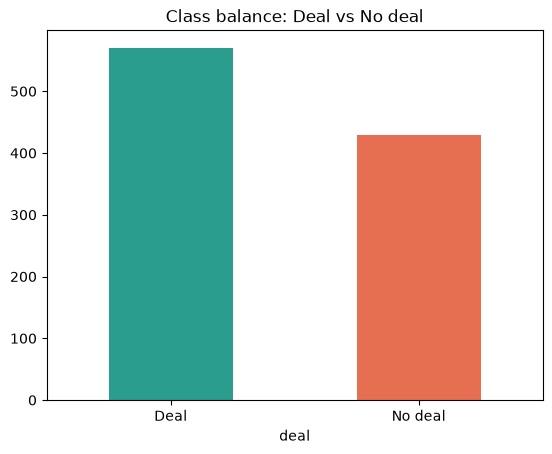

In [5]:
# ── Cell 5 ──
df["deal"] = (df["Accepted Offer"] == 1).astype(int)
counts = df["deal"].value_counts().rename({1: "Deal", 0: "No deal"})
print(counts.to_string(), f"\n\nDeal rate: {df['deal'].mean():.1%}")
counts.plot.bar(color=["#2a9d8f", "#e76f51"], rot=0, title="Class balance: Deal vs No deal"); plt.show()

**Class balance:** 57% Deal / 43% No deal, roughly balanced. 🤔 A lazy model that *always* says "Deal" is already right **57%** of the time. That's our **baseline**: any model we build must beat 57%, or it's useless.

# Phase 2 · EDA (Exploratory Data Analysis): the detective work 🕵️

Before any model, a data scientist **studies the data**, like CID's ACP Pradyuman walking into a crime scene: *"Daya, kuch toh gadbad hai."* 🔍

**The standard EDA checklist** (every Kaggle notebook and every data team does some version of this):
1. **First look:** how big is it, what are the columns, what types?
2. **Summary statistics:** what's typical, what's extreme?
3. **Missing values:** what's blank, and why?
4. **One column at a time** (univariate): what does each column look like?
5. **Column vs answer** (bivariate): which columns move with *Deal*?
6. **Red flags:** leakage, impossible values, outliers
7. **Write down the findings** → they become the cleaning plan

## 2.1 First look: meet the suspects

In [6]:
# ── Cell 6 ──
df.head()      # first 5 rows, all columns

,Season Number,Episode Number,Pitch Number,Startup Name,Industry,Business Description,Started in,Number of Presenters,Male Presenters,Female Presenters,...,Original Ask Amount,Original Offered Equity,Valuation Requested,Received Offer,Accepted Offer,Total Deal Amount,Total Deal Equity,Deal Valuation,Number of Sharks in Deal,deal
0,1,1,1,AanganSpace,Lifestyle/Home,Handmade decor,NaN,4,3,1,...,40.0,4.00,1000.0,0,NaN,NaN,NaN,NaN,NaN,0
1,1,1,2,OfficePartners,Business Services,Corporate gifting,2018.0,2,2,0,...,60.0,1.50,4000.0,0,NaN,NaN,NaN,NaN,NaN,0
2,1,1,3,KesarFresh,Food and Beverage,Healthy millet snacks,NaN,2,2,0,...,200.0,1.00,20000.0,1,1.0,400.0,2.68,14925.37,2.0,1
3,1,1,4,SutraLabel,Beauty/Fashion,Plus-size ethnic wear,2017.0,1,1,0,...,35.0,3.50,1000.0,1,1.0,35.0,4.02,870.65,3.0,1
4,1,2,5,SutraWear,Beauty/Fashion,Handloom sarees online,2017.0,2,2,0,...,90.0,1.25,7200.0,1,1.0,90.0,2.72,3308.82,3.0,1


In [7]:
# ── Cell 7 ──
df.drop(columns="deal").info()      # the 32 raw columns (we only *view* a copy without our new 'deal' column)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 32 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Season Number             1000 non-null   int64  
 1   Episode Number            1000 non-null   int64  
 2   Pitch Number              1000 non-null   int64  
 3   Startup Name              1000 non-null   object 
 4   Industry                  1000 non-null   object 
 5   Business Description      1000 non-null   object 
 6   Started in                895 non-null    float64
 7   Number of Presenters      1000 non-null   int64  
 8   Male Presenters           1000 non-null   int64  
 9   Female Presenters         1000 non-null   int64  
 10  Couple Presenters         1000 non-null   int64  
 11  Pitchers Average Age      1000 non-null   object 
 12  Pitchers City             965 non-null    object 
 13  Pitchers State            971 non-null    object 
 14  Yearly Re

**How to read `info()`:**
- **RangeIndex: 1000 entries** → 1,000 rows, one per pitch.
- **Non-Null Count** → how many rows actually have a value. `Net Margin` has only **456 of 1,000**: our first hint of blanks.
- **Dtype** (data type):
  - `int64` = whole numbers (Season Number: 1, 2, 3…)
  - `float64` = decimal numbers (Gross Margin: 57.5)
  - `object` = text (Industry: "Food and Beverage")

🤔 **Two surprises:**
- `Started in` is a year, so why `float64` and not `int64`? Because it has **blanks**: pandas stores a blank as `NaN`, and `NaN` only fits in a float column.
- `Cash Burn`, `Has Patents`, `Bootstrapped` are `object` (text): they hold "yes"/"no", which a model can't read directly yet.

**Know your columns.** Every column must be understood before it's used. Our 32 columns fall into 5 groups:

| Group | Columns | Useful for predicting? |
|---|---|---|
| 🆔 **IDs and labels** (5) | Season Number, Episode Number, Pitch Number, Startup Name, Business Description | ❌ names and serial numbers don't make a startup good |
| 🏢 **About the startup and founders** (9) | Industry, Started in, Number of Presenters, Male / Female / Couple Presenters, Pitchers Average Age, Pitchers City, Pitchers State | 🤔 maybe: EDA will tell |
| 💰 **Business health** (9) | Yearly Revenue, Monthly Sales, Gross Margin, Net Margin, EBITDA, Cash Burn, SKUs, Has Patents, Bootstrapped | ✅ likely |
| 🤝 **The ask** (3) | Original Ask Amount, Original Offered Equity, Valuation Requested | ✅ likely |
| 🔒 **After the pitch** (6) | Received Offer, Accepted Offer, Total Deal Amount, Total Deal Equity, Deal Valuation, Number of Sharks in Deal | ⛔ only known *after* the decision (see 2.6) |

We **don't delete** any column yet: EDA only *labels* them. The final choice of model inputs happens in Feature Engineering (Phase 4).

In [8]:
# ── Cell 8 ──
df.drop(columns="deal").nunique().sort_values()    # how many different values each column has

Couple Presenters              2
Bootstrapped                   2
Has Patents                    2
Received Offer                 2
Accepted Offer                 2
Cash Burn                      2
Pitchers Average Age           3
Season Number                  5
Female Presenters              5
Number of Presenters           5
Number of Sharks in Deal       5
Male Presenters                6
Pitchers State                16
Industry                      17
Original Offered Equity       19
Started in                    23
Pitchers City                 24
Original Ask Amount           29
Total Deal Amount             55
Episode Number                58
Gross Margin                  86
Business Description          90
Valuation Requested          116
SKUs                         179
Net Margin                   293
EBITDA                       354
Total Deal Equity            419
Monthly Sales                442
Deal Valuation               509
Yearly Revenue               524
Startup Na

**How to read `nunique()`:**
- **2 values** (Cash Burn, Has Patents, Bootstrapped, Couple Presenters, Received/Accepted Offer) → yes/no columns.
- **3–24 values** (Season, Age group, Industry 17, City 24) → **categories**.
- **1,000 values** (Pitch Number, Startup Name) → a different value in **every row**: these are **IDs**, like a roll number. Your roll number doesn't decide your marks! ❌

In [9]:
# ── Cell 9 ──
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate pitches (ignoring IDs and names):", df.drop(columns=["Pitch Number", "Startup Name", "Episode Number"]).duplicated().sum())

Duplicate rows: 0
Duplicate pitches (ignoring IDs and names): 0


**Duplicates: 0.** 🎉 If the same pitch appeared twice, the model would "study" it twice, and if one copy landed in the test set, it would see an exam question it already knows. **Always check, even when the answer is zero.**

## 2.2 Summary statistics: what's typical, what's extreme?

In [10]:
# ── Cell 10 ──
with pd.option_context("display.float_format", "{:,.1f}".format):    # 1 decimal, only for this table
    display(df.drop(columns="deal").describe().T)

,count,mean,std,min,25%,50%,75%,max
Season Number,"1,000.0",3.0,1.4,1.0,2.0,3.0,4.0,5.0
Episode Number,"1,000.0",25.7,14.8,1.0,13.0,25.5,38.0,58.0
Pitch Number,"1,000.0",500.5,288.8,1.0,250.8,500.5,750.2,"1,000.0"
Started in,895.0,"2,020.3",8.4,"1,920.0","2,018.0","2,020.0","2,022.0","2,201.0"
Number of Presenters,"1,000.0",2.0,0.8,1.0,1.0,2.0,2.0,5.0
Male Presenters,"1,000.0",1.5,0.9,0.0,1.0,1.0,2.0,5.0
Female Presenters,"1,000.0",0.6,0.7,0.0,0.0,0.0,1.0,4.0
Couple Presenters,"1,000.0",0.1,0.3,0.0,0.0,0.0,0.0,1.0
Yearly Revenue,922.0,658.3,"2,762.1",0.0,66.0,188.0,491.5,"52,000.0"
Monthly Sales,761.0,64.7,241.0,0.0,4.7,15.3,45.1,"4,053.5"


**How to read `describe()`:**
- **count** = filled rows (blanks aren't counted)
- **mean** = average · **50%** = median (the middle value) · **min / max** = smallest / largest
- **25% / 75%** = a quarter of the rows are below / above these values

🚨 *Daya, kuch toh gadbad hai…*
- `Original Ask Amount`: typical (median) ask **₹70 lakh**, but the max is **25,000,000 lakh**?!
- `Gross Margin`: max **550%**? You can't keep more than 100% of what you sell.
- `Started in`: min **1920**, max **2201**?! 🛸
- `Yearly Revenue`: mean far above the median → a few giants pull the average up.
- The **count** column is below 1,000 for many columns → **blanks**. Let's look at those first.

## 2.3 Missing values: the blank-cell trap

Rows left if we delete every row with ANY blank cell: 64 out of 1000


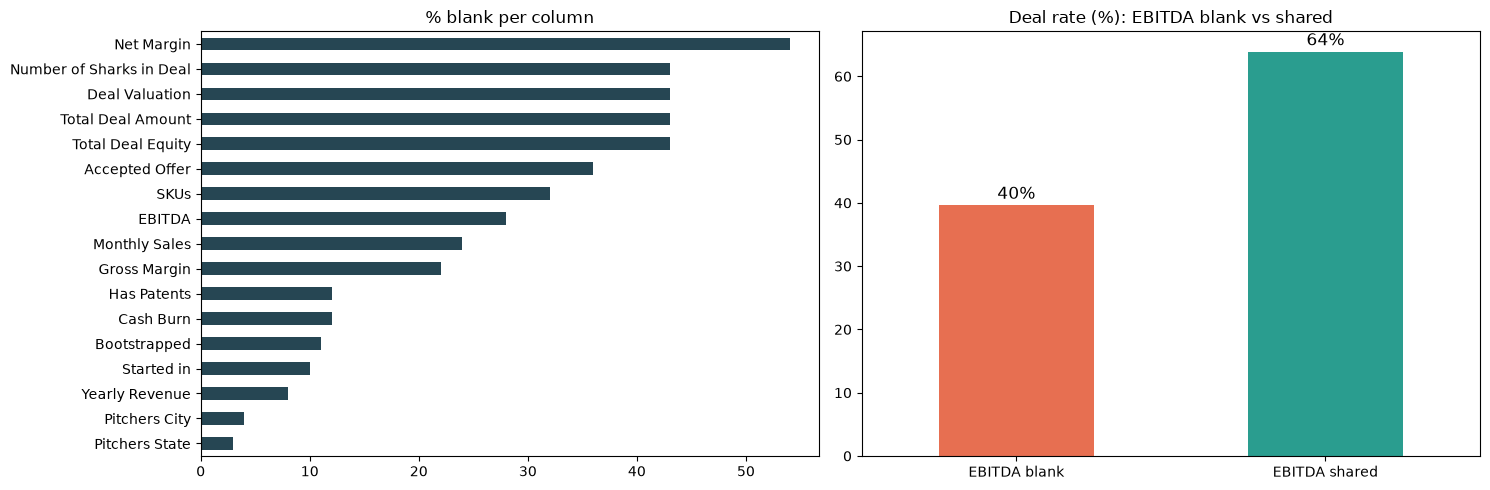

In [11]:
# ── Cell 11 ──
print("Rows left if we delete every row with ANY blank cell:", len(df.dropna()), "out of", len(df))
eda_blank = (df.drop(columns="deal").isna().mean() * 100).round(0)
eda_ebitda = df.groupby(df["EBITDA"].isna().map({False: "EBITDA shared", True: "EBITDA blank"}))["deal"].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
eda_blank[eda_blank > 0].sort_values().plot.barh(ax=axes[0], color="#264653", title="% blank per column")
eda_ebitda.plot.bar(ax=axes[1], color=["#e76f51", "#2a9d8f"], rot=0, title="Deal rate (%): EBITDA blank vs shared", xlabel="")
for i, v in enumerate(eda_ebitda):
    axes[1].text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=12)
plt.tight_layout(); plt.show()

😱 **Only 64 of 1,000 rows survive** if we delete blanks: we'd throw away 94% of our data. So we **won't delete** them; they get **filled** later (Phase 6).

**Left chart:** the after-the-pitch columns (Total Deal Amount, Deal Valuation, …) are blank when there was **no deal**: nothing to write, so those blanks are correct. **Net Margin** is often not recorded.

**Right chart:** when **EBITDA** (profit) is blank, only **40%** get a deal vs **64%** when it's shared. 🤔 Founders who are **losing money** don't like to show it, and Sharks notice.

**Lesson 1: a blank can be a clue.** (Phase 4 turns this into a *"Did they share EBITDA?"* column.)

## 2.4 One column at a time (univariate analysis)

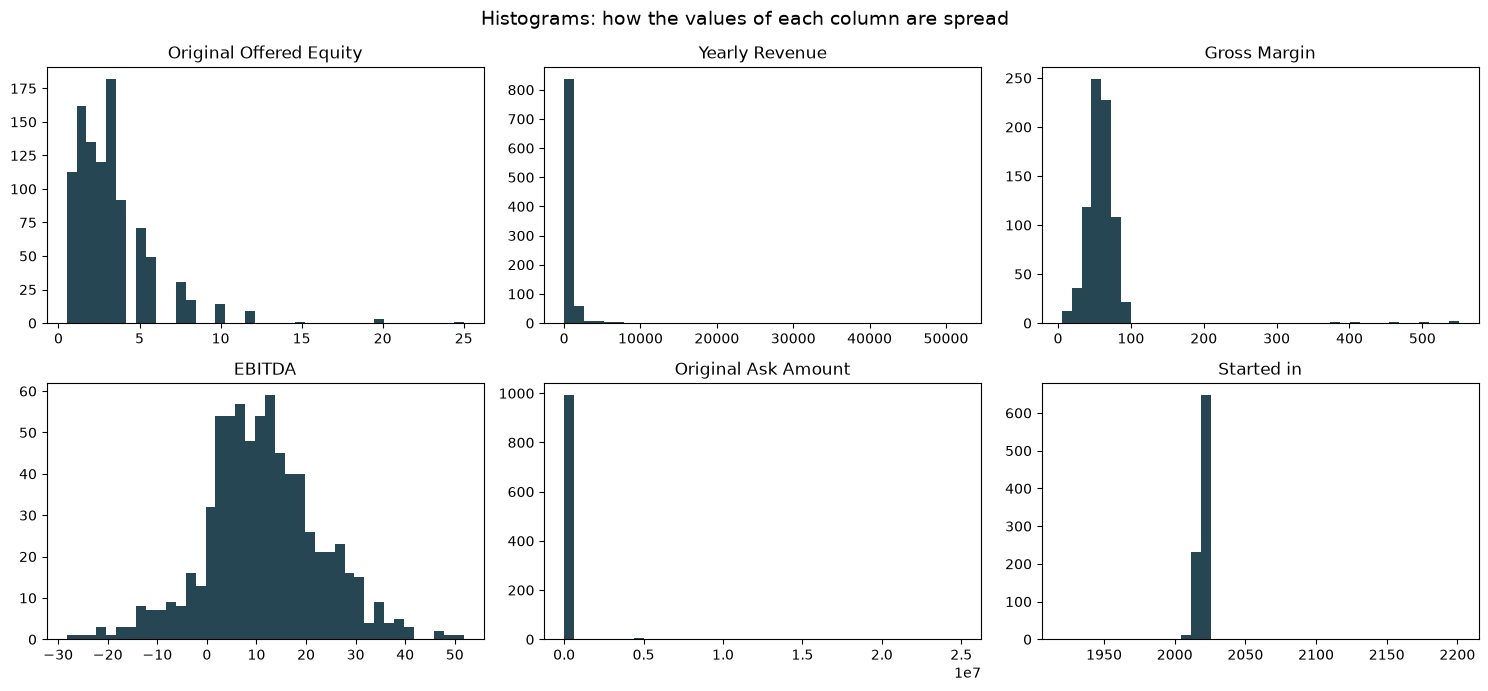

In [12]:
# ── Cell 12 ──
eda_num = ["Original Offered Equity", "Yearly Revenue", "Gross Margin", "EBITDA", "Original Ask Amount", "Started in"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), eda_num):
    ax.hist(df[col].dropna(), bins=40, color="#264653")
    ax.set_title(col)
plt.suptitle("Histograms: how the values of each column are spread", fontsize=14)
plt.tight_layout(); plt.show()

**How to read a histogram:** the x-axis is the value, the bar height is *how many pitches* have that value.

| Chart | What you see | What it means |
|---|---|---|
| **Equity** | most founders offer **1–5%**, a few offer 15–25% | founders don't like giving away much |
| **Gross Margin** | a nice hill around **50–65%**… but the x-axis stretches to 550 | a few weird values far right 🚩 |
| **EBITDA** | most are positive (profitable), a tail goes negative | some startups lose money |
| **Yearly Revenue** | one giant bar near 0 and an endless tail | **skewed**: a few huge companies (see below) |
| **Ask** | *everything* is squashed into one bar | a few values are SO huge they break the chart 🚩 |
| **Started in** | one bar, the axis runs from 1920 to 2201 | impossible years 🚩 |

🔍 **If a histogram looks broken, the data is usually broken.** The 🚩 ones are investigated in 2.7.

Mean revenue: ₹658 lakh   |   Median revenue: ₹188 lakh
5 biggest revenues (₹ lakh): [18000.0, 25000.0, 32000.0, 41000.0, 52000.0]


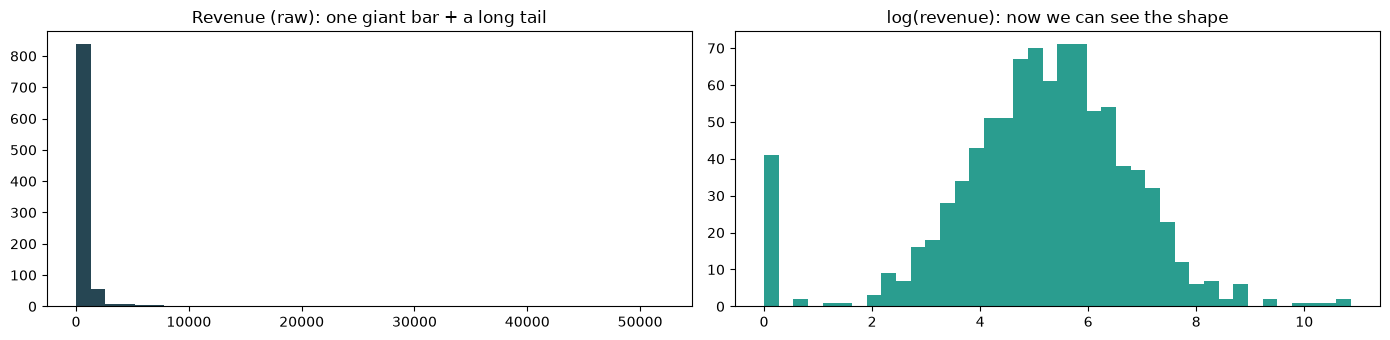

In [13]:
# ── Cell 13 ──
eda_rev = df["Yearly Revenue"].dropna()
print(f"Mean revenue: ₹{eda_rev.mean():,.0f} lakh   |   Median revenue: ₹{eda_rev.median():,.0f} lakh")
print("5 biggest revenues (₹ lakh):", sorted(eda_rev.nlargest(5).tolist()))
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
axes[0].hist(eda_rev, bins=40, color="#264653"); axes[0].set_title("Revenue (raw): one giant bar + a long tail")
axes[1].hist(np.log1p(eda_rev), bins=40, color="#2a9d8f"); axes[1].set_title("log(revenue): now we can see the shape")
plt.tight_layout(); plt.show()

A few companies make **₹180–520 crore** a year. Errors? **No!** These numbers are *possible*: big brands do come on the show. So we **keep** them.

But they cause two problems:
1. **The average lies.** Mean ₹658 lakh vs median ₹188 lakh. It's like Ambani walking into a chai tapri: suddenly the "average income" in the room is in crores. The **median** stays honest.
2. **The chart is squashed.** Taking the **log** makes ₹10 L, ₹100 L and ₹1,000 L evenly spaced, so we can see the real shape (right chart).

**Lesson 2: a real outlier is kept and tamed with a log.** (Phase 4 uses this.)

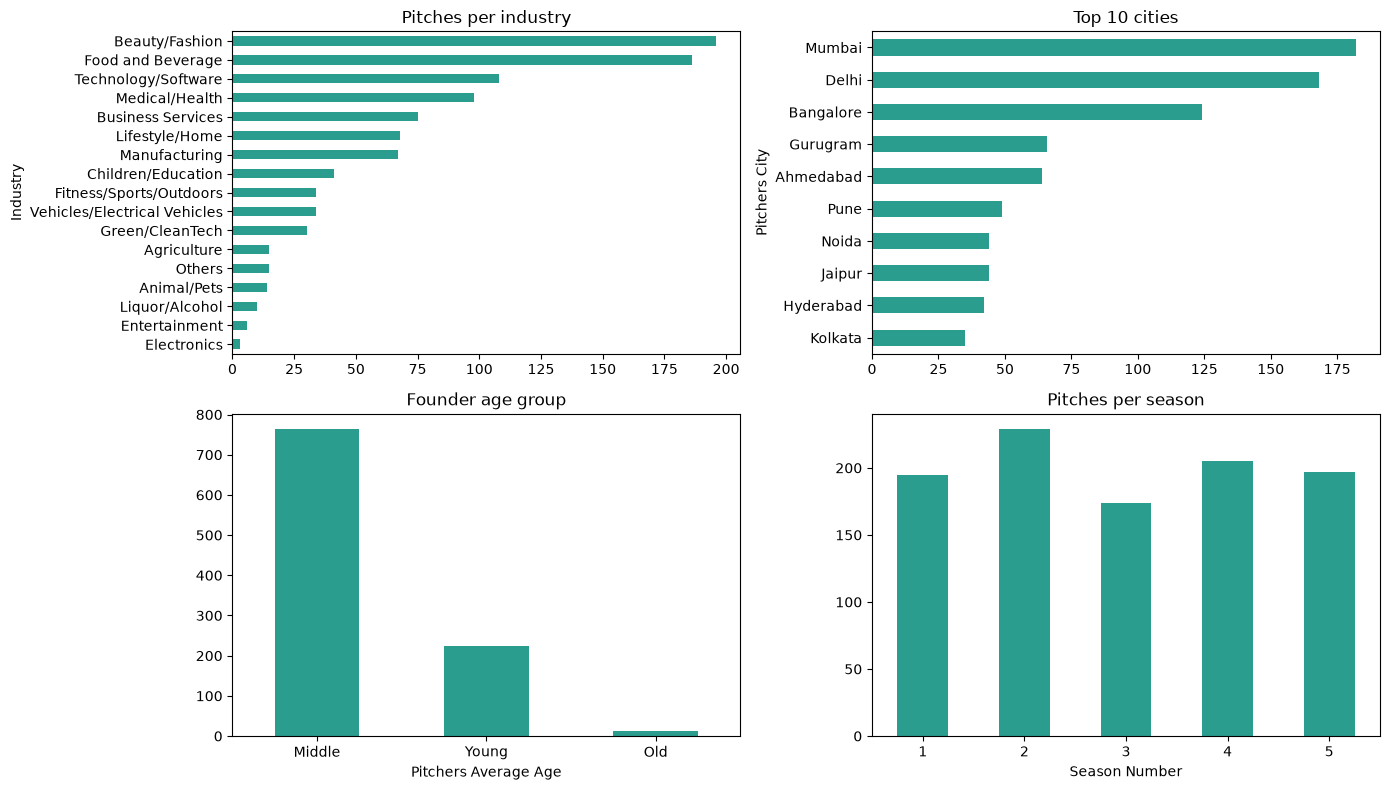

In [14]:
# ── Cell 14 ──
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
df["Industry"].value_counts().sort_values().plot.barh(ax=axes[0, 0], color="#2a9d8f", title="Pitches per industry")
df["Pitchers City"].value_counts().head(10).sort_values().plot.barh(ax=axes[0, 1], color="#2a9d8f", title="Top 10 cities")
df["Pitchers Average Age"].value_counts().plot.bar(ax=axes[1, 0], color="#2a9d8f", rot=0, title="Founder age group")
df["Season Number"].value_counts().sort_index().plot.bar(ax=axes[1, 1], color="#2a9d8f", rot=0, title="Pitches per season")
plt.tight_layout(); plt.show()

**Count plots** show how often each category appears:
- **Industry:** Beauty/Fashion and Food & Beverage dominate (D2C brands love Shark Tank!). **Electronics has only 3 pitches**: too few to learn anything reliable.
- **City:** Mumbai, Delhi, Bangalore lead, the startup capitals. Smaller cities have a handful each.
- **Age:** almost everyone is "Middle"; "Old" is barely there.
- **Season:** about 200 pitches per season, nicely even.

**A category with very few rows can't teach the model much.**

## 2.5 Column vs answer (bivariate analysis): what moves with *Deal*?

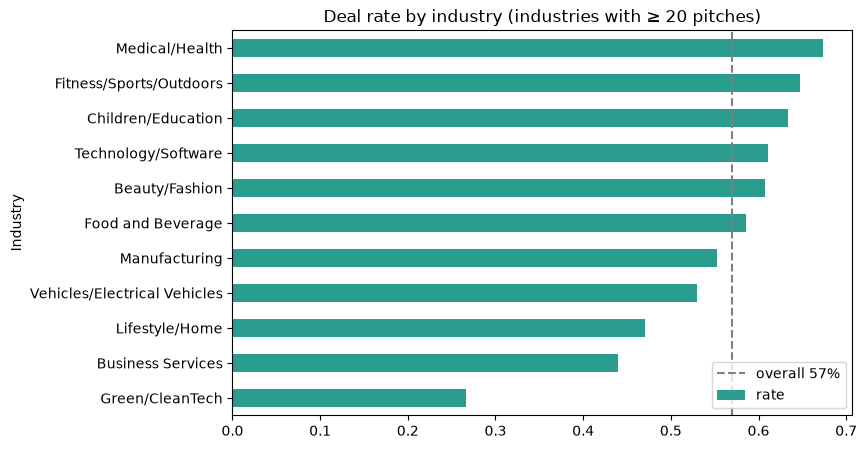

Too small to judge (< 20 pitches):
                rate  pitches
Industry                     
Entertainment   0.33        6
Animal/Pets     0.50       14
Liquor/Alcohol  0.50       10
Agriculture     0.60       15
Others          0.60       15
Electronics     0.67        3


In [15]:
# ── Cell 15 ──
eda_ind = df.groupby("Industry")["deal"].agg(rate="mean", pitches="count").sort_values("rate")
eda_big = eda_ind[eda_ind["pitches"] >= 20]
ax = eda_big["rate"].plot.barh(color="#2a9d8f", figsize=(8, 5), title="Deal rate by industry (industries with ≥ 20 pitches)")
ax.axvline(df["deal"].mean(), ls="--", c="grey", label=f"overall {df['deal'].mean():.0%}"); ax.legend(); plt.show()
print("Too small to judge (< 20 pitches):"); print(eda_ind[eda_ind["pitches"] < 20].round(2).to_string())

**What you see:** each bar is the % of pitches in that industry that got a deal; the dashed line is the overall 57%.
**What it means:** Sharks have favourite sectors: **Medical/Health (67%)** and **Fitness (65%)** do best, while **Green/CleanTech (27%)** and **Business Services (44%)** struggle. Industry will be a useful input.
⚠️ The tiny industries are listed separately: a 100% or 0% deal rate from 3 pitches proves nothing.

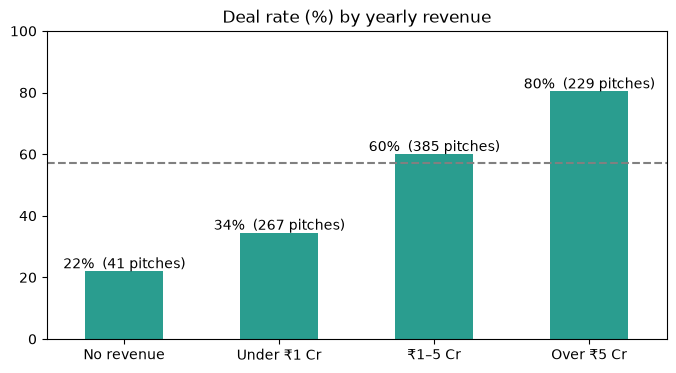

In [16]:
# ── Cell 16 ──
eda_band = pd.cut(df["Yearly Revenue"], [-1, 0, 100, 500, np.inf],
                  labels=["No revenue", "Under ₹1 Cr", "₹1–5 Cr", "Over ₹5 Cr"])
eda_by_band = df.groupby(eda_band, observed=True)["deal"].agg(rate="mean", pitches="count")
ax = (eda_by_band["rate"] * 100).plot.bar(color="#2a9d8f", rot=0, figsize=(8, 4), title="Deal rate (%) by yearly revenue")
for i, (r, n) in enumerate(zip(eda_by_band["rate"], eda_by_band["pitches"])):
    ax.text(i, r * 100 + 1, f"{r:.0%}  ({n} pitches)", ha="center")
ax.axhline(df["deal"].mean() * 100, ls="--", c="grey"); ax.set_ylim(0, 100); ax.set_xlabel(""); plt.show()

**What you see:** the bars climb like stairs: **22% → 34% → 60% → 80%**.
**What it means:** the more revenue, the more deals. Sharks love **traction** (proof that customers pay). But even "No revenue" gets 22% and "Over ₹5 Cr" still misses 20%: revenue alone can't decide. The model needs *many* clues together.

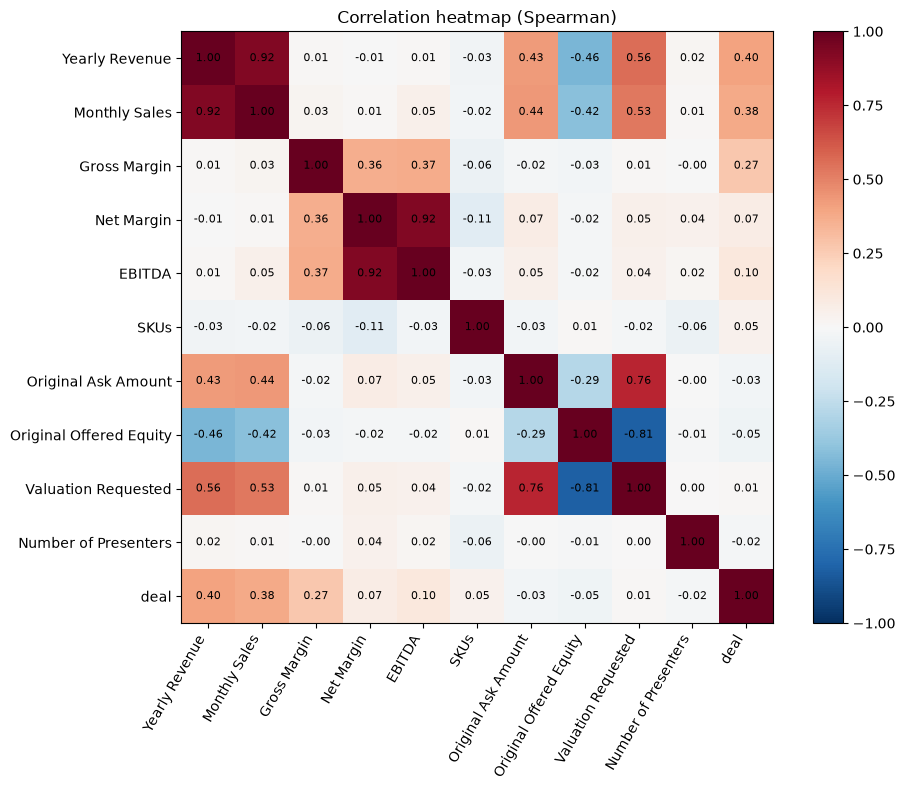

In [17]:
# ── Cell 17 ──
eda_cols = ["Yearly Revenue", "Monthly Sales", "Gross Margin", "Net Margin", "EBITDA", "SKUs",
            "Original Ask Amount", "Original Offered Equity", "Valuation Requested", "Number of Presenters", "deal"]
eda_corr = df[eda_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(eda_corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(eda_cols))); ax.set_xticklabels(eda_cols, rotation=60, ha="right")
ax.set_yticks(range(len(eda_cols))); ax.set_yticklabels(eda_cols)
for i in range(len(eda_cols)):
    for j in range(len(eda_cols)):
        ax.text(j, i, f"{eda_corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im); plt.title("Correlation heatmap (Spearman)"); plt.tight_layout(); plt.show()

**How to read a correlation heatmap:** each square shows how strongly two columns move together, from **−1** (one goes up, the other goes down) through **0** (no link) to **+1** (they rise together). Red = positive, blue = negative.

**What you see:**
- 🔴 **Monthly Sales ↔ Yearly Revenue** and **Net Margin ↔ EBITDA** are deep red: twins telling the same story (more on this in Feature Engineering).
- 🔵 **Equity ↔ Valuation** is deep blue: offering a *bigger* % means you value your company *lower*.
- In the **deal** row, the strongest link is **Yearly Revenue (0.40, medium)**; most others are close to 0. No single column decides a deal alone.

⚠️ **Correlation ≠ causation.** Ice-cream sales and drowning both rise in summer. Ice cream doesn't cause drowning! 🍦🏊

## 2.6 Red flag #1: the cheating column (leakage)

In [18]:
# ── Cell 18 ──
rule = df["Total Deal Amount"].notna().astype(int)   # "if a deal amount is written, predict Deal"
print(f"Accuracy of this one-line rule: {(rule == df['deal']).mean():.0%}")

Accuracy of this one-line rule: 100%


🎉 **100% accurate!** Did we just solve Shark Tank?

…No. `Total Deal Amount` is only written **after** the Sharks say yes. When a new founder walks in, it doesn't exist yet. Using it is like reading the answer key during the exam. This is called **data leakage**.

**The time-machine test:** *"Would I know this column at the moment the founder starts pitching?"* If not, it can't be an input.

🦈 **Remember the game at the start?** I hid the `Accepted Offer` column on purpose. If you could have seen it, you'd have scored 4 out of 4 without thinking, just like this 100% rule. **That's leakage:** the answer sneaking into the inputs. A model trained like that looks like a genius in class and fails in real life.

In [19]:
# ── Cell 19 ──
LEAKAGE = ["Received Offer", "Accepted Offer", "Total Deal Amount", "Total Deal Equity", "Deal Valuation", "Number of Sharks in Deal"]
print("Columns that fail the time-machine test:", LEAKAGE)

Columns that fail the time-machine test: ['Received Offer', 'Accepted Offer', 'Total Deal Amount', 'Total Deal Equity', 'Deal Valuation', 'Number of Sharks in Deal']


## 2.7 Red flag #2: numbers that can't be true

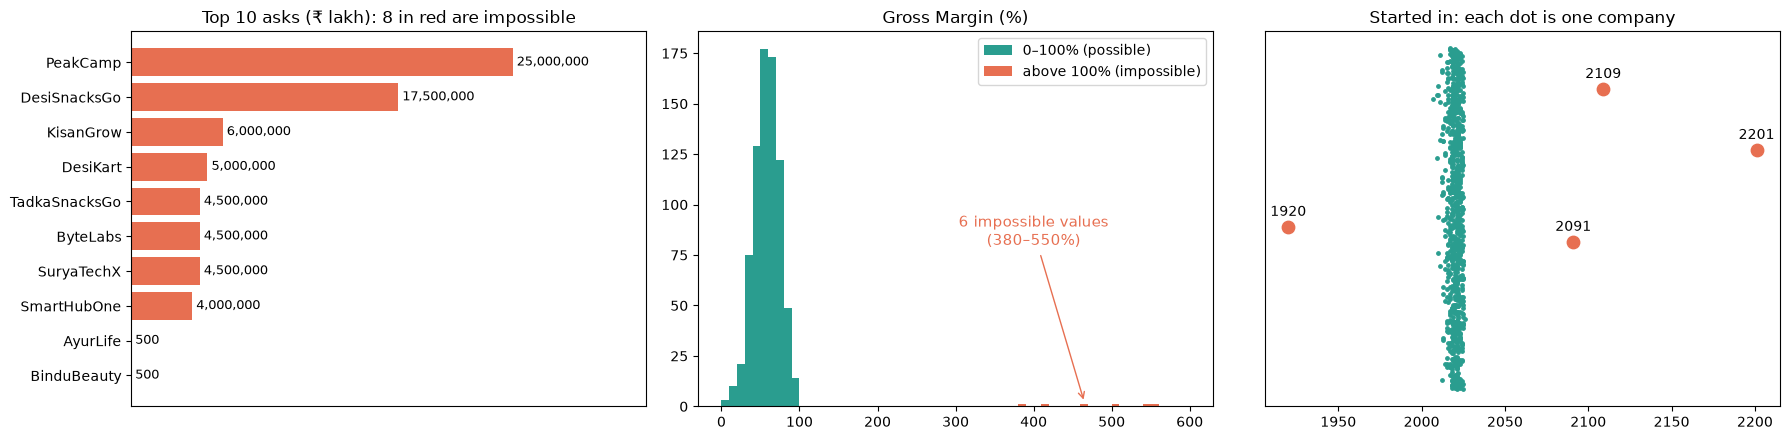

Impossible asks: 8 | Margins above 100%: 6 | Impossible years: [1920, 2091, 2109, 2201]


In [20]:
# ── Cell 20 ──
broken = df["Original Ask Amount"] > 10000      # an ask above ₹100 crore (10,000 lakh): impossible on the show
eda_top = df.nlargest(10, "Original Ask Amount").set_index("Startup Name")["Original Ask Amount"][::-1]
eda_gm = df["Gross Margin"].dropna()
eda_yr = df["Started in"].dropna()
eda_bad_yr = ~eda_yr.between(1990, 2026)
eda_jitter = np.random.default_rng(0).uniform(-1, 1, len(eda_yr))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].barh(eda_top.index, eda_top, color=["#e76f51" if v > 10000 else "#2a9d8f" for v in eda_top])
for i, v in enumerate(eda_top):
    axes[0].text(v, i, f" {v:,.0f}", va="center", fontsize=9)
axes[0].set_xticks([]); axes[0].set_xlim(0, eda_top.max() * 1.35)
axes[0].set_title("Top 10 asks (₹ lakh): 8 in red are impossible")
eda_bins = np.arange(0, 601, 10)
axes[1].hist(eda_gm[eda_gm <= 100], bins=eda_bins, color="#2a9d8f", label="0–100% (possible)")
axes[1].hist(eda_gm[eda_gm > 100], bins=eda_bins, color="#e76f51", label="above 100% (impossible)")
axes[1].annotate("6 impossible values\n(380–550%)", xy=(465, 2), xytext=(400, 80), ha="center", color="#e76f51",
                 fontsize=11, arrowprops=dict(arrowstyle="->", color="#e76f51"))
axes[1].set_title("Gross Margin (%)"); axes[1].legend()
axes[2].scatter(eda_yr[~eda_bad_yr], eda_jitter[~eda_bad_yr], s=6, c="#2a9d8f")
axes[2].scatter(eda_yr[eda_bad_yr], eda_jitter[eda_bad_yr], s=80, c="#e76f51")
for y, j in zip(eda_yr[eda_bad_yr], eda_jitter[eda_bad_yr]):
    axes[2].annotate(f"{y:.0f}", (y, j), textcoords="offset points", xytext=(0, 8), ha="center")
axes[2].set_yticks([]); axes[2].set_title("Started in: each dot is one company")
plt.tight_layout(); plt.show()

print("Impossible asks:", broken.sum(), "| Margins above 100%:", (eda_gm > 100).sum(),
      "| Impossible years:", sorted(eda_yr[eda_bad_yr].astype(int).tolist()))

**What you see:**
- **Asks:** the typical ask is ₹70 lakh and the biggest honest ask is ₹500 lakh (so small its bar is invisible!). The 8 red ones are ₹40 lakh lakh and up. 🕵️ Look at **ByteLabs: 45,00,000**. That's ₹45 lakh typed in **rupees** instead of **lakh**. A **unit error**: right number, wrong unit → divide by 1,00,000.
- **Gross Margin:** a normal hill below 100%, and 6 red values at 380–550%. Really 38–55% typed with an extra zero → divide by 10.
- **Started in:** almost every company started 2007–2026. Then **1920, 2091, 2109, 2201**: time travellers 🛸. We can't guess the real year → make it blank (filled later).

⚠️ **Not every extreme value is an error.** The ₹520 Cr revenue (2.4) is *possible*, so we kept it. The question is always: **can this value exist in real life?**

## 2.8 EDA findings: the detective's report 📝

| # | Finding | Evidence | What we'll do |
|---|---|---|---|
| 1 | Target defined | 570 deals / 430 no-deals (57%) | Baseline to beat: 57% |
| 2 | Blanks everywhere | `dropna()` keeps only 64 rows | Don't delete, fill them (Phase 6) |
| 3 | A blank can be a clue | EBITDA blank: 40% deals vs 64% | Keep a "shared?" flag (Phase 4) |
| 4 | Huge but real revenue | ₹180–520 Cr | **Keep**, tame with a log (Phase 4) |
| 5 | Deals depend on many columns | revenue stairs 22% → 80%, industry 27–67% | Use them as features (Phase 4) |
| 6 | Leakage | Total Deal Amount → 100% "accuracy" | Never use the 6 after-the-pitch columns |
| 7 | Unit errors | 8 asks typed in rupees, not lakh | **Fix now** ÷ 1,00,000 |
| 8 | Impossible margins | 6 values of 380–550% | **Fix now** ÷ 10 |
| 9 | Impossible years | 1920, 2091, 2109, 2201 | **Fix now** → blank |

Rows 7–9 are broken data → let's clean. 🧹

# Phase 3 · Cleaning

In [21]:
# ── Cell 21 ──
clean = df.copy()
clean.loc[broken, "Original Ask Amount"] /= 100000                 # rupees → lakh
clean.loc[clean["Gross Margin"] > 100, "Gross Margin"] /= 10       # 550 → 55
clean.loc[~clean["Started in"].between(1990, 2026), "Started in"] = np.nan   # time travellers → blank (filled later)

check = (clean["Original Ask Amount"] / clean["Original Offered Equity"] * 100 / clean["Valuation Requested"]).round(2) != 1
print("Broken asks left:", check.sum(), "| Margins > 100% left:", (clean["Gross Margin"] > 100).sum(),
      "| Max ask now: ₹", clean["Original Ask Amount"].max(), "lakh")
print(f"Rows: {len(df)} → {len(clean)} (we fixed rows instead of deleting them)")

Broken asks left: 0 | Margins > 100% left: 0 | Max ask now: ₹ 500.0 lakh
Rows: 1000 → 1000 (we fixed rows instead of deleting them)


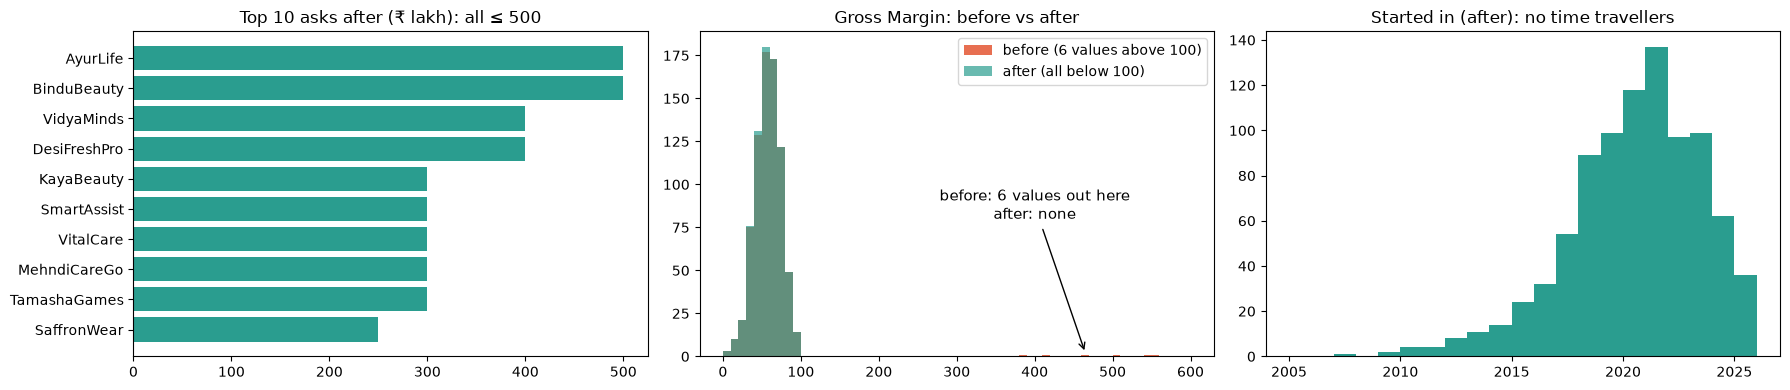

In [22]:
# ── Cell 22 ──
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
eda_top_after = clean.nlargest(10, "Original Ask Amount").set_index("Startup Name")["Original Ask Amount"][::-1]
axes[0].barh(eda_top_after.index, eda_top_after, color="#2a9d8f")
axes[0].set_title("Top 10 asks after (₹ lakh): all ≤ 500")
axes[1].hist(df["Gross Margin"].dropna(), bins=eda_bins, color="#e76f51", label="before (6 values above 100)")
axes[1].hist(clean["Gross Margin"].dropna(), bins=eda_bins, color="#2a9d8f", alpha=0.7, label="after (all below 100)")
axes[1].annotate("before: 6 values out here\nafter: none", xy=(465, 2), xytext=(400, 80), ha="center",
                 fontsize=11, arrowprops=dict(arrowstyle="->"))
axes[1].set_title("Gross Margin: before vs after"); axes[1].legend()
axes[2].hist(clean["Started in"].dropna(), bins=np.arange(2005, 2027), color="#2a9d8f")
axes[2].set_title("Started in (after): no time travellers")
plt.tight_layout(); plt.show()

**Cleaning log:**

| Problem | Rows | Fix | Why not delete the row? |
|---|---|---|---|
| Ask typed in rupees | 8 | ÷ 1,00,000 | The rest of the pitch is fine; we know the true value |
| Margin typed ×10 | 6 | ÷ 10 | Same: an obvious typo with a clear fix |
| Impossible start year | 4 | → blank | We can't guess the true year, so we fill it later |
| Huge real revenue | 5 | kept | It's real! A log tames it in Phase 4 |

## 🤖 Bonus: the automatic EDA report

Everything we just did by hand (`info()`, `describe()`, histograms, blanks, deal rates, correlations), a library can generate **in one go**: **data profiling**. We use `fg-data-profiling`, the new name of the popular **ydata-profiling** (formerly *pandas-profiling*).

Run the next cell (it takes about **30 seconds**). The report appears below and is also saved as **`eda_report.html`** (open it in any browser). Explore its tabs:

| Section | What it shows | We did it in |
|---|---|---|
| **Overview** | rows, columns, % missing, duplicates, column types | 2.1 |
| **Alerts** | ⚠️ automatic warnings: high correlation, many blanks, skewed, unique IDs | the whole EDA |
| **Variables** | one card per column: stats + histogram (**univariate**) | 2.2, 2.4 |
| **Interactions** | every number column vs `deal` (**bivariate**) | 2.5 |
| **Correlations** | the heatmap, plus a table | 2.5 |
| **Missing values** | where the blanks are | 2.3 |
| **Sample / Duplicates** | first & last rows, repeated rows | 2.1 |

⚠️ **A tool can't think for you.** It shows `Total Deal Amount` as a column like any other: it doesn't know that's **leakage**. And it sees an ask of 45,00,000 as just a big number: only *we* knew it was rupees typed instead of lakh. Use the report to **find** suspects fast; the detective work is still yours. 🕵️

In [23]:
# ── Cell 23 ──
# Automatic EDA report: everything we did by hand, in one go (takes ~30 seconds)
from data_profiling import ProfileReport    # pip install fg-data-profiling  (the new name of ydata-profiling)

eda_report = ProfileReport(
    df,                                      # the raw data, exactly as we received it
    title="Shark Tank India (simulated): automatic EDA report",
    interactions={"targets": ["deal"]},      # scatter plots of each column vs the answer (bivariate)
    progress_bar=False,
)
eda_report.to_file("eda_report.html")       # a copy you can open in any browser
eda_report.to_notebook_iframe()             # show the report right here

  0%|          | 0/33 [00:00<?, ?it/s]

 12%|█▏        | 4/33 [00:00<00:02, 12.34it/s]

100%|██████████| 33/33 [00:00<00:00, 89.16it/s]

Cleaning done: target defined, leakage identified, unit errors fixed, impossible values blanked, real outliers kept. Now the fun part: **think like a Shark**.

# Phase 4 · Feature Engineering: think like a Shark
🤔 A founder asks **₹50 lakh for 5%**, and their company makes **₹1 crore a year**. What are they *really* claiming?

In [24]:
# ── Cell 24 ──
ask, equity, revenue = 50, 5, 100
valuation = ask / equity * 100
print(f"₹{ask} lakh for {equity}%  →  company worth ₹{valuation / 100:.0f} Cr")
print(f"Revenue ₹{revenue / 100:.0f} Cr  →  they want {valuation / revenue:.0f}× their yearly revenue")

₹50 lakh for 5%  →  company worth ₹10 Cr
Revenue ₹1 Cr  →  they want 10× their yearly revenue


That number, **valuation ÷ revenue** (the *multiple*), is exactly what Sharks calculate in their heads: *"You want 10 times your sales? Justify it!"* Does the data agree?

        rate  pitches
≤5×     0.85      188
5–10×   0.72      169
10–20×  0.61      218
20–30×  0.48       96
30–60×  0.35      119
>60×    0.05       91


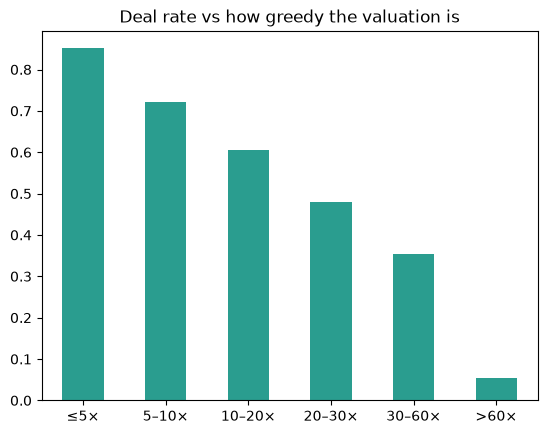

In [25]:
# ── Cell 25 ──
has_rev = clean["Yearly Revenue"] > 0
multiple = clean["Valuation Requested"] / clean["Yearly Revenue"].where(has_rev)
buckets = pd.cut(multiple, [0, 5, 10, 20, 30, 60, np.inf], labels=["≤5×", "5–10×", "10–20×", "20–30×", "30–60×", ">60×"])
by_mult = clean.groupby(buckets, observed=True)["deal"].agg(rate="mean", pitches="count")
print(by_mult.round(2))
by_mult["rate"].plot.bar(color="#2a9d8f", rot=0, title="Deal rate vs how greedy the valuation is"); plt.show()

🔥 **The greed wall.** Ask for up to 5× your revenue → **85%** get a deal. Ask for more than 60× → only **5%**. One engineered column captures the Sharks' most famous question.

What else do Sharks care about? Let's compare groups.

In [26]:
# ── Cell 26 ──
profit = np.select([clean["EBITDA"] > 0, clean["EBITDA"] <= 0], ["profitable", "loss-making"], "not shared")
print(clean.groupby(profit)["deal"].agg(rate="mean", pitches="count").round(2), "\n")
gm_q = pd.qcut(clean["Gross Margin"], 4, labels=["lowest 25%", "low-mid", "mid-high", "highest 25%"])
print("Deal rate by Gross Margin:\n", clean.groupby(gm_q, observed=True)["deal"].mean().round(2).to_string())

             rate  pitches
loss-making  0.42       81
not shared   0.40      285
profitable   0.67      634 



Deal rate by Gross Margin:
 Gross Margin
lowest 25%     0.40
low-mid        0.56
mid-high       0.72
highest 25%    0.72


- **Profitable** startups get a deal **67%** of the time vs **42%** for loss-making ones. And "not shared" behaves like loss-making: the clue from Lesson 1 again!
- **Higher gross margin → more deals.** Earning ₹60 on every ₹100 sold beats earning ₹30.

In [27]:
# ── Cell 27 ──
DEEP_TECH = ["Technology/Software", "Medical/Health", "Manufacturing", "Vehicles/Electrical Vehicles",
             "Green/CleanTech", "Agriculture", "Electronics"]
kind = np.where(clean["Industry"].isin(DEEP_TECH), "deep-tech", "consumer brand")
pd.crosstab(kind, clean["Has Patents"], values=clean["deal"], aggfunc="mean").round(2)

Has Patents,no,yes
row_0,,
consumer brand,0.57,0.53
deep-tech,0.51,0.74


🤔 **Do patents help?** It depends!
- For **deep-tech** (software, medical devices, EVs…), a patent lifts the deal rate from **51% → 74%**: it protects the technology.
- For **consumer brands** (snacks, clothes…), a patent changes nothing (**57% vs 53%**). Nobody funds a samosa because of its patent.

When one factor's effect **depends on another**, that's called an **interaction**. A model won't always find it alone, so we build a column for it: *"patent AND deep-tech"*.

In [28]:
# ── Cell 28 ──
city = clean.groupby("Pitchers City")["deal"].agg(rate="mean", pitches="count").sort_values("rate")
print("Lowest:\n", city.head(3).round(2).to_string(), "\n\nHighest:\n", city.tail(3).round(2).to_string())

Lowest:
                rate  pitches
Pitchers City               
Chandigarh     0.38        8
Nagpur         0.50        8
Patna          0.50        2 

Highest:
                rate  pitches
Pitchers City               
Indore         0.73       11
Surat          0.76       17
Vadodara       0.85       13


😮 Vadodara founders get **85%** deals and Chandigarh only **38%**! Should we move to Vadodara?

Look at **pitches**: only 8–17 per city (Patna has just 2!). Flip a coin 13 times and you can easily get 11 heads. With so few pitches, a big difference can be **pure luck**. The big cities (Mumbai, Delhi, Bangalore) all sit near the average.

**Lesson 3: small groups lie.** Before trusting a difference, check how many rows are behind it. We'll **not** use city.

In [29]:
# ── Cell 29 ──
pairs = [("Monthly Sales", "Yearly Revenue"), ("Net Margin", "EBITDA")]
for a, b in pairs:
    print(f"{a} vs {b}: correlation {clean[[a, b]].corr(method='spearman').iloc[0, 1]:.2f}")

Monthly Sales vs Yearly Revenue: correlation 0.92
Net Margin vs EBITDA: correlation 0.92


**Monthly Sales** is basically Yearly Revenue ÷ 12, and **Net Margin** is EBITDA minus interest and tax. Correlation **0.92**: they tell the model the *same story twice*. They also have more blanks (24% and 54%). So we keep **one from each pair**: Yearly Revenue and EBITDA. Same information, fewer blanks.

**Lesson 4: more columns ≠ more information.**

Now we turn everything we learned into the model's input columns:

In [30]:
# ── Cell 30 ──
X = pd.DataFrame(index=clean.index)
# the ask: log shrinks huge numbers (Lesson 2)
X["log_ask"]        = np.log1p(clean["Original Ask Amount"])
X["equity_pct"]     = clean["Original Offered Equity"]
# traction and greed
X["log_revenue"]    = np.log1p(clean["Yearly Revenue"])                    # blank if not shared
X["log_multiple"]   = np.log(clean["Valuation Requested"] / clean["Yearly Revenue"].where(has_rev))   # blank if no revenue (can't divide by 0)
# money health
X["gross_margin"]   = clean["Gross Margin"]
X["ebitda"]         = clean["EBITDA"]
X["ebitda_shared"]  = clean["EBITDA"].notna().astype(int)                  # a blank can be a clue (Lesson 1)
X["cash_burn"]      = clean["Cash Burn"].map({"yes": 1, "no": 0})
# moat and founders
X["has_patents"]     = clean["Has Patents"].map({"yes": 1, "no": 0})
X["patent_deeptech"] = (X["has_patents"].fillna(0) * clean["Industry"].isin(DEEP_TECH)).astype(int)   # interaction
X["bootstrapped"]    = clean["Bootstrapped"].map({"yes": 1, "funded": 0})
X["company_age"]     = (2021 + clean["Season Number"]) - clean["Started in"]   # Season 1 aired in 2021-22
# industry: text for now
X["industry"] = clean["Industry"]
y = clean["deal"]
print(f"Features: {X.shape[1]} columns (from {df.shape[1] - 1} raw columns) | Rows: {X.shape[0]}")
X.head()

Features: 13 columns (from 32 raw columns) | Rows: 1000


,log_ask,equity_pct,log_revenue,log_multiple,gross_margin,ebitda,ebitda_shared,cash_burn,has_patents,patent_deeptech,bootstrapped,company_age,industry
0,3.713572,4.00,3.784190,3.146555,57.0,1.4,1,0.0,0.0,0,1.0,NaN,Lifestyle/Home
1,4.110874,1.50,3.988984,4.323758,52.0,12.9,1,0.0,0.0,0,0.0,4.0,Business Services
2,5.303305,1.00,NaN,NaN,33.0,NaN,0,1.0,1.0,0,1.0,NaN,Food and Beverage
3,3.583519,3.50,6.272877,0.636767,59.0,7.1,1,0.0,0.0,0,1.0,5.0,Beauty/Fashion
4,4.510860,1.25,7.221836,1.660731,77.0,14.0,1,0.0,0.0,0,0.0,5.0,Beauty/Fashion


**Our 13 features**, each with a reason:

| Feature | Why a Shark cares |
|---|---|
| `log_ask`, `equity_pct` | the deal on the table |
| `log_revenue` | traction: are customers paying? |
| `log_multiple` ✨ | greed: valuation ÷ revenue |
| `gross_margin`, `ebitda` | is the business healthy? |
| `ebitda_shared` ✨ | hiding numbers is a red flag |
| `cash_burn` | burning money every month? |
| `has_patents`, `patent_deeptech` ✨ | is the idea protected, and does it matter here? |
| `bootstrapped` | built with their own money? |
| `company_age` ✨ | how long they've survived |
| `industry` | Sharks have favourite sectors |

✨ = a new column we **engineered** (made ourselves).

**Not used, and why:**

| Columns | Reason |
|---|---|
| Received/Accepted Offer, Total Deal Amount/Equity, Deal Valuation, Number of Sharks in Deal | ⛔ leakage (only known after the pitch) |
| Valuation Requested | already inside `log_ask`, `equity_pct`, and `log_multiple` (it's just ask ÷ equity × 100) |
| Monthly Sales, Net Margin | repeat Yearly Revenue and EBITDA (Lesson 4) |
| Pitchers City, State | small groups, luck (Lesson 3) |
| Startup Name, Business Description, Pitch/Episode Number | names and IDs, not business facts |
| Presenters, gender, age group, SKUs, Season | no link to deals in our EDA |

# Phase 5 · Train/Test Split: the sealed exam

In [31]:
# ── Cell 31 ──
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Train (study material): {len(X_train)} rows | Deal rate {y_train.mean():.1%}")
print(f"Test  (sealed exam)   : {len(X_test)} rows | Deal rate {y_test.mean():.1%}")

Train (study material): 800 rows | Deal rate 57.0%
Test  (sealed exam)   : 200 rows | Deal rate 57.0%


If you study from the *exact* exam paper you'll score 100%, but you've learned nothing. So we lock **20%** away as the exam and never peek until the very end. `stratify=y` keeps the same 57% deal rate in both parts, so the exam is fair.

# Phase 6 · Preprocessing: make the data model-ready

🤔 Three problems are left: (1) some features have **blanks**, (2) industry is **text**, (3) numbers live on **very different scales**.

In [32]:
# ── Cell 32 ──
print("Blanks per feature (train):"); print(X_train.isna().sum()[lambda s: s > 0].to_string())
print(f"\nRanges: gross_margin {X_train['gross_margin'].min():.0f}–{X_train['gross_margin'].max():.0f} | "
      f"company_age {X_train['company_age'].min():.0f}–{X_train['company_age'].max():.0f} | has_patents 0–1")

Blanks per feature (train):
log_revenue      65
log_multiple     97
gross_margin    173
ebitda          223
cash_burn        93
has_patents      99
bootstrapped     81
company_age      88

Ranges: gross_margin 5–92 | company_age 0–15 | has_patents 0–1


- **Blanks → fill (imputation):** replace a missing value with the **median**, the typical value. We *can't* just delete rows (remember: only 64 survive!). For the EBITDA blanks we already saved the clue in `ebitda_shared`.
- **Text → numbers (one-hot encoding):** `industry = "Medical/Health"` becomes a column `Medical/Health = 1`, others 0. Industries with fewer than 20 pitches are grouped as *"other"* (small groups lie!).
- **Different scales → same scale (standardising):** gross margin goes up to 92, has_patents only to 1. Scaling puts every number around 0, so no column shouts louder just because its numbers are bigger.

⚠️ The preprocessor **learns from the training data only** (the medians, the scales). If it peeked at the test set, the exam wouldn't be sealed anymore.

In [33]:
# ── Cell 33 ──
NUM = [c for c in X.columns if c != "industry"]
CAT = ["industry"]
preprocessor = ColumnTransformer([
    ("numbers", Pipeline([("fill_blanks", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), NUM),
    ("industry", OneHotEncoder(min_frequency=20, handle_unknown="infrequent_if_exist", sparse_output=False), CAT),
])
demo = preprocessor.fit(X_train)                     # learn from TRAIN only
Xt_train, Xt_test = demo.transform(X_train), demo.transform(X_test)
print(f"Before preprocessing: {X_train.shape[1]} columns  →  after: {Xt_train.shape[1]} columns")
print("Blanks left:", int(np.isnan(Xt_train).sum()))
print("Industry columns created:", [n.replace("industry__industry_", "") for n in demo.get_feature_names_out() if n.startswith("industry__")])

Before preprocessing: 13 columns  →  after: 24 columns
Blanks left: 0
Industry columns created: ['Beauty/Fashion', 'Business Services', 'Children/Education', 'Fitness/Sports/Outdoors', 'Food and Beverage', 'Green/CleanTech', 'Lifestyle/Home', 'Manufacturing', 'Medical/Health', 'Technology/Software', 'Vehicles/Electrical Vehicles', 'infrequent_sklearn']


No blanks, everything is numeric, and everything is on a fair scale. ✅

# 🤝 Handoff to Part 2 (Model Training)

In [34]:
# ── Cell 34 ──
handoff = {"X_train": X_train, "X_test": X_test, "y_train": y_train, "y_test": y_test,
           "preprocessor": preprocessor,              # unfitted recipe: Part 2 fits it inside the model pipeline
           "numeric_features": NUM, "categorical_features": CAT}
joblib.dump(handoff, "handoff_part1.joblib")
print(f"Saved handoff_part1.joblib → {len(X_train)} train / {len(X_test)} test rows, {X.shape[1]} features")
print("Baseline to beat: always 'Deal' =", f"{y_test.mean():.1%}", "on the test set")

Saved handoff_part1.joblib → 800 train / 200 test rows, 13 features


Baseline to beat: always 'Deal' = 57.0% on the test set


## Recap: what we learned

| Step | The 🤔 moment | The lesson |
|---|---|---|
| Problem | 357 blank answers | A blank can *mean* something (no offer) |
| EDA | `dropna()` leaves 64 of 1,000 rows | Don't delete blanks: fill them |
| EDA | EBITDA blank → 40% deals vs 64% | A blank can be a clue: keep a flag |
| EDA | A one-line rule is 100% accurate | Leakage: use only what's known at pitch time |
| EDA | An ask of ₹2.5 lakh crore | Unit errors: check columns against each other |
| EDA | 550% margin vs ₹520 Cr revenue | Fix errors, keep real outliers (use a log) |
| Feature Engineering | 85% deals at ≤5× vs 5% at >60× | Turn the Shark's mental math into a column |
| Feature Engineering | Patents help only deep-tech | Interactions: one factor depends on another |
| Feature Engineering | Vadodara 85% on 13 pitches | Small groups lie |
| Feature Engineering | Monthly Sales ≈ Revenue ÷ 12 | More columns ≠ more information |
| Split | The sealed exam | Never peek at the test set |
| Preprocessing | Blanks, text, different scales | Impute, one-hot encode, scale: fitted on train only |

# Part 2 · Parth | Train your deal predictor

| Minutes | What happens |
|---|---|
| 0–3 | Ask the room to vote on a ₹50 lakh for 5% pitch. Explain Deal / No Deal and the Always Deal baseline. |
| 3–9 | Everyone runs Logistic Regression. Explain the probability curve, then change the decision threshold once. |
| 9–14 | Facilitator reveals Random Forest and Gradient Boosting. Explain voting and successive corrections with the pictures. |
| 14–20 | Reveal the scorecard. Find the CV winner and ask the room to read two kinds of mistakes from its confusion matrix. |

In a live session, start from the handoff with Part 1 already run. The facilitator can run the full notebook once ahead of time so the result figures are also available as saved outputs.

### Stage 1 · Three ways to reach a verdict

Start with the left panel. Save the two tree panels for the reveal. All three illustrations are simplified examples.

**What does this code do?** Display the three model approaches and prepare the model-training section.

**What are we doing here?** We introduce a baseline and tree-based approaches for comparison. The diagrams and imports prepare students for the model stages.

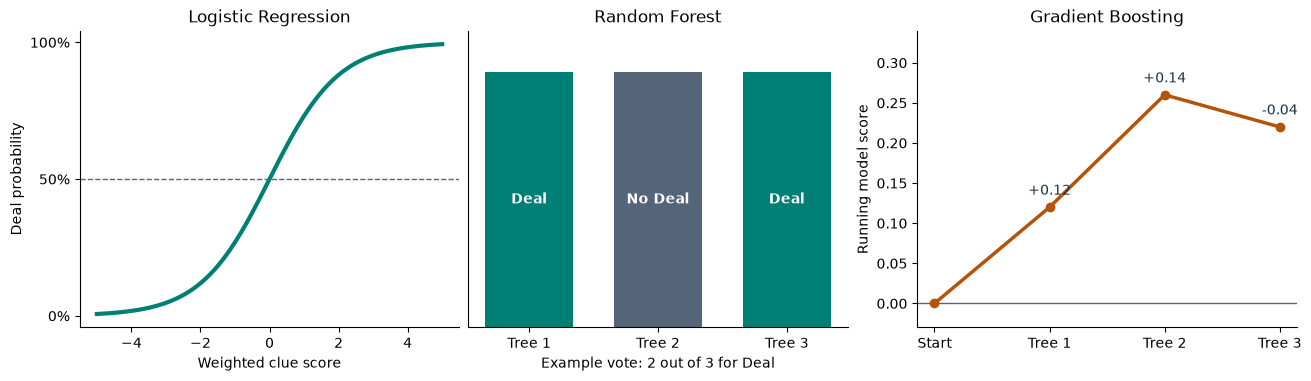

In [35]:
# ── Cell 35 ──
from sklearn.base import clone   # copies the unfitted preprocessing recipe for each model
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
    f1_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate

navy, teal, orange, muted = "#183249", "#007f75", "#b45309", "#546579"
fig, (ax_log, ax_rf, ax_gb) = plt.subplots(1, 3, figsize=(13, 3.7), layout="constrained")
score = np.linspace(-5, 5, 200)
ax_log.plot(score, 1 / (1 + np.exp(-score)), color=teal, lw=3)
ax_log.axhline(.5, color=muted, linestyle="--", lw=1)
ax_log.set(title="Logistic Regression", xlabel="Weighted clue score", ylabel="Deal probability",
           yticks=[0, .5, 1])
ax_log.set_yticklabels(["0%", "50%", "100%"])

votes = ["Deal", "No Deal", "Deal"]
ax_rf.bar(["Tree 1", "Tree 2", "Tree 3"], [1, 1, 1], color=[teal, muted, teal], width=.68)
for index, vote in enumerate(votes):
    ax_rf.text(index, .50, vote, ha="center", va="center", color="white", weight="bold")
ax_rf.set(title="Random Forest", xlabel="Example vote: 2 out of 3 for Deal", ylim=(0, 1.16), yticks=[])

totals = [0, .12, .26, .22]
ax_gb.axhline(0, color=muted, lw=1)
ax_gb.plot(range(4), totals, marker="o", lw=2.5, color=orange)
for step, change in enumerate(np.diff(totals), start=1):
    ax_gb.annotate(f"{change:+.2f}", (step, totals[step]), xytext=(0, 9),
                   textcoords="offset points", ha="center", color=navy)
ax_gb.set(title="Gradient Boosting", ylabel="Running model score", ylim=(-.03, .34),
          xticks=range(4), xticklabels=["Start", "Tree 1", "Tree 2", "Tree 3"])
for axis in (ax_log, ax_rf, ax_gb):
    axis.spines[["top", "right"]].set_visible(False)
plt.show()

### Stage 2 · Run Logistic Regression together

Logistic Regression combines weighted clues and maps the score to a number between 0 and 1. The threshold turns that score into a verdict. Use one practice pitch from the training set to see those two steps.

**What does this code do?** Create and train a Logistic Regression pipeline, then calculate a sample pitch’s Deal probability.

**What are we doing here?** We combine preprocessing and Logistic Regression into one pipeline. The model learns from the training set and returns a probability for a sample pitch.

In [36]:
# ── Cell 36 ──
X_train, y_train = handoff["X_train"], handoff["y_train"]
logistic = Pipeline([
    ("preprocess", clone(handoff["preprocessor"])),
    ("model", LogisticRegression(max_iter=1000)),
])
logistic.fit(X_train, y_train)

practice_pitch = X_train.iloc[[0]]
deal_probability = logistic.predict_proba(practice_pitch)[0, 1]
pitch = clean.loc[practice_pitch.index[0]]
print(f"{pitch['Industry']} pitch | Ask: ₹{pitch['Original Ask Amount']:g} lakh "
      f"for {pitch['Original Offered Equity']:g}% equity")
print(f"Practice-pitch deal probability: {deal_probability:.1%}")

Business Services pitch | Ask: ₹250 lakh for 0.75% equity
Practice-pitch deal probability: 84.7%


Student activity. Set the threshold below the displayed probability and run the next cell. Set it above the probability and run it again. Discuss what changed. You used the same pitch and trained model both times.

**What does this code do?** Change the probability threshold and convert the model score into a Deal or No Deal verdict.

**What are we doing here?** We demonstrate that the threshold controls the decision. Lowering it generally predicts more Deals; raising it generally predicts fewer.

In [37]:
# ── Cell 37 ──
threshold = 0.50  # Try a value below, then above, the displayed probability
verdict = "Deal" if deal_probability >= threshold else "No Deal"
print(f"Probability {deal_probability:.1%} | threshold {threshold:.0%} | verdict: {verdict}")

Probability 84.7% | threshold 50% | verdict: Deal


### Stage 3 · Reveal the two tree models

- **Random Forest:** many trees see different samples and consider different clues. In the sketch they cast votes. In this implementation their class probabilities are averaged.
- **Gradient Boosting:** trees are added one at a time to improve the current combined model. The running score can move up or down as a tree contributes a correction.

The next cell is for the facilitator. Each model uses the same stratified five folds of the 800 training pitches. We select by mean CV F1 for Deal, which balances precision and recall. The standard 50% cutoff is used for the comparison, independent of the student activity.

**What does this code do?** Train and prepare the baseline, Random Forest and Gradient Boosting pipelines.

**What are we doing here?** We compare a simple Always Deal baseline with two tree-ensemble models. Each pipeline receives its own copy of the preprocessing recipe.

In [38]:
# ── Cell 38 ──
seed = 42
pipelines = {
    "Always Deal": Pipeline([
        ("preprocess", clone(handoff["preprocessor"])),
        ("model", DummyClassifier(strategy="most_frequent")),
    ]),
    "Logistic Regression": logistic,
    "Random Forest": Pipeline([
        ("preprocess", clone(handoff["preprocessor"])),
        ("model", RandomForestClassifier(n_estimators=100, min_samples_leaf=5, random_state=seed)),
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocess", clone(handoff["preprocessor"])),
        ("model", GradientBoostingClassifier(max_depth=2, random_state=seed)),
    ]),
}
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
training_rows = []
for name, pipeline in pipelines.items():
    scores = cross_validate(
        pipeline, X_train, y_train, cv=folds,
        scoring=("f1", "balanced_accuracy", "roc_auc"), error_score="raise",
    )
    training_rows.append({
        "Model": name,
        "CV Deal F1": scores["test_f1"].mean(),
        "CV F1 Std": scores["test_f1"].std(),
        "CV Balanced Acc.": scores["test_balanced_accuracy"].mean(),
        "CV ROC AUC": scores["test_roc_auc"].mean(),
    })
training_scores = pd.DataFrame(training_rows).set_index("Model")
winner = training_scores.drop(index="Always Deal")["CV Deal F1"].idxmax()
print(f"Selected on training-fold Deal F1: {winner}")

Selected on training-fold Deal F1: Logistic Regression


### Stage 4 · Open the sealed test set

Accuracy counts all correct verdicts. Balanced accuracy gives Deal and No Deal equal weight. Deal F1 combines precision and recall for the Deal class. ROC AUC measures how well the scores rank Deal above No Deal across thresholds.

Ask the room to identify a missed Deal and a predicted Deal that was actually No Deal. Read the counts from the confusion matrix. The held-out numbers measure performance on simulated pitches.

**What does this code do?** Evaluate the trained models on the sealed test set and collect evaluation metrics.

**What are we doing here?** We predict only on the held-out test pitches and calculate metrics such as accuracy, balanced accuracy, Deal F1 and ROC AUC.

In [39]:
# ── Cell 39 ──
X_test, y_test = handoff["X_test"], handoff["y_test"]
test_rows = []
predictions = {}
for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    predicted = pipeline.predict(X_test)
    probability = pipeline.predict_proba(X_test)[:, 1]
    predictions[name] = predicted
    test_rows.append({
        "Model": name,
        "Test Accuracy": accuracy_score(y_test, predicted),
        "Test Balanced Acc.": balanced_accuracy_score(y_test, predicted),
        "Test Deal F1": f1_score(y_test, predicted, zero_division=0),
        "Test ROC AUC": roc_auc_score(y_test, probability),
    })

results = training_scores.join(pd.DataFrame(test_rows).set_index("Model"))
display(results.round(3))

,CV Deal F1,CV F1 Std,CV Balanced Acc.,CV ROC AUC,Test Accuracy,Test Balanced Acc.,Test Deal F1,Test ROC AUC
Model,,,,,,,,
Always Deal,0.726,0.002,0.500,0.500,0.570,0.500,0.726,0.500
Logistic Regression,0.794,0.022,0.756,0.839,0.790,0.774,0.828,0.840
Random Forest,0.789,0.027,0.736,0.818,0.770,0.758,0.807,0.839
Gradient Boosting,0.787,0.020,0.736,0.823,0.775,0.764,0.810,0.837


**What does this code do?** Plot model rankings and confusion matrices for the test-set predictions.

**What are we doing here?** We visualise overall performance and the types of mistakes made by each model. A confusion matrix separates correct and incorrect Deal/No Deal predictions.

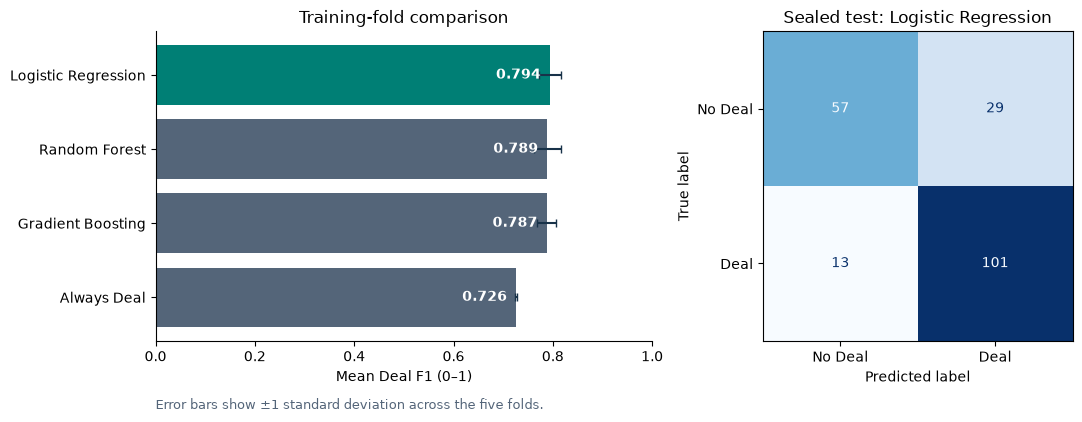

In [40]:
# ── Cell 40 ──
fig, (ax_rank, ax_matrix) = plt.subplots(1, 2, figsize=(11, 4.1),
                                        gridspec_kw={"width_ratios": [1.35, 1]},
                                        layout="constrained")
ordered = results["CV Deal F1"].sort_values(kind="stable")
colors = [teal if name == winner else muted for name in ordered.index]
bars = ax_rank.barh(ordered.index, ordered, color=colors, xerr=results.loc[ordered.index, "CV F1 Std"],
                     error_kw={"capsize": 3, "ecolor": navy})
ax_rank.set(title="Training-fold comparison", xlabel="Mean Deal F1 (0–1)", xlim=(0, 1))
for rect, value in zip(bars, ordered):
    ax_rank.text(value - .018, rect.get_y() + rect.get_height() / 2, f"{value:.3f}",
                 ha="right", va="center", color="white", weight="bold")
ax_rank.text(0, -.22, "Error bars show ±1 standard deviation across the five folds.",
             fontsize=9, color=muted, transform=ax_rank.transAxes)
ax_rank.spines[["top", "right"]].set_visible(False)

ConfusionMatrixDisplay.from_predictions(
    y_test, predictions[winner], labels=[0, 1], display_labels=["No Deal", "Deal"],
    cmap="Blues", colorbar=False, ax=ax_matrix,
)
ax_matrix.set_title(f"Sealed test: {winner}")
plt.show()

Close with one question: If a team wanted to catch more actual deals, which kinds of mistakes might increase when it lowers the threshold?

### Stage 5 — Interactive pitch desk

Run the cells below to open the dashboard here. Change the equity, submit the pitch, then click the photo to reveal the model score. Use Model results to compare the models. For a larger classroom view, open the generated simulated_pitch_dashboard.html in a browser. In Colab, you can download it from the Files panel.

Presenter cue. The pitch inputs are the detective’s clues. Changing the cutoff changes how much evidence the detective needs to call a Deal.

**What does this code do?** Create the interactive pitch desk and connect the dashboard to the selected trained model.

**What are we doing here?** We build the classroom interface so students can enter pitch details and inspect model predictions. Run this after the model pipelines have been trained.

In [41]:
# ── Cell 41 ──
# Use the pipeline selected on the training folds and fitted in Stage 4.
from pathlib import Path
import json
from sklearn.metrics import confusion_matrix

selected = pipelines[winner]
prep = selected.named_steps["preprocess"]
estimator = selected.named_steps["model"]
numbers = prep.named_transformers_["numbers"]
scaler = numbers.named_steps["scale"]
encoder = prep.named_transformers_["industry"]
industries = sorted(X_train["industry"].dropna().unique().tolist())
encoded = encoder.transform(pd.DataFrame({"industry": industries}))

def export_tree(tree, classification=False):
    structure = tree.tree_
    values = structure.value[:, 0, :]
    leaf_value = values[:, 1] / values.sum(axis=1) if classification else values[:, 0]
    return dict(left=structure.children_left.tolist(), right=structure.children_right.tolist(),
                feature=structure.feature.tolist(), threshold=structure.threshold.tolist(),
                value=leaf_value.tolist())

if isinstance(estimator, LogisticRegression):
    model_data = dict(kind="logistic", weights=estimator.coef_[0].tolist(),
                      intercept=float(estimator.intercept_[0]))
elif isinstance(estimator, RandomForestClassifier):
    model_data = dict(kind="forest", trees=[export_tree(t, True) for t in estimator.estimators_])
elif isinstance(estimator, GradientBoostingClassifier):
    prior = estimator.init_.class_prior_
    model_data = dict(kind="boost", intercept=float(np.log(prior[1] / prior[0])),
                      rate=estimator.learning_rate,
                      trees=[export_tree(t) for t in estimator.estimators_[:, 0]])
else:
    raise TypeError(f"Unsupported estimator for dashboard: {type(estimator).__name__}")

dashboard_data = dict(
    winner=winner, model=model_data, numeric=NUM, industries=dict(zip(industries, encoded.tolist())),
    median=numbers.named_steps["fill_blanks"].statistics_.tolist(),
    mean=scaler.mean_.tolist(), scale=scaler.scale_.tolist(), deepTech=DEEP_TECH,
    train=len(X_train), test=len(X_test), matrix=confusion_matrix(y_test, predictions[winner], labels=[0,1]).tolist(),
    metrics=results[["CV Deal F1","Test Accuracy","Test Balanced Acc."]].to_dict("index"),
)

# Each industry's ask and equity axes use only the training pitches.
quantiles = np.linspace(0, 1, 9)
dashboard_data["boards"] = {
    name: {
        "asks": np.unique(np.expm1(np.quantile(group["log_ask"], quantiles)).round(6)).tolist(),
        "equities": np.unique(np.quantile(group["equity_pct"], quantiles).round(6)).tolist(),
    }
    for name, group in X_train.groupby("industry")
}

### Dashboard layout cell (original notebook cell 75)

This very large cell contains the dashboard’s embedded HTML, styling and photo assets. Keep and run this original cell unchanged when building the interactive pitch desk.

Run it once (it only defines the layout and two reaction photos), then run the next cell to open the pitch desk.

In [42]:
# ── Cell 42 ──
#@title Dashboard layout and embedded photos
# Run this cell once. The next cell connects it to the fitted model.
DASHBOARD_TEMPLATE = '<!doctype html><html lang="en"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Deal ya Doglapan? · Pitch desk</title>\n<style>\n*{box-sizing:border-box}body{margin:0;background:#f4f6f5;color:#17312f;font:16px/1.45 \'Segoe UI\',Arial,sans-serif}main{max-width:1160px;margin:auto;padding:22px clamp(14px,4vw,48px) 36px}header{background:#123631;color:white;padding:24px clamp(18px,4vw,44px);border-radius:16px}h1{font-size:clamp(30px,5vw,52px);letter-spacing:-.05em;line-height:1.05;margin:8px 0}header p{margin:6px 0;color:#c6e4d9}.club{font-weight:700;color:#a6e1ce}nav{display:flex;gap:6px;margin:18px 0}button{font:inherit;cursor:pointer}nav button,.submit{border:0;border-radius:8px;font-weight:650;padding:10px 18px}nav button{background:#e3ebe7;color:#284440}nav button[aria-pressed=true],.submit{background:#155a4e;color:white}button:focus-visible,input:focus-visible,select:focus-visible,summary:focus-visible{outline:3px solid #cb8422;outline-offset:2px}.layout{display:grid;grid-template-columns:1.08fr 1fr;gap:18px;align-items:start}.panel{background:white;padding:clamp(16px,3vw,25px);border:1px solid #d7e1dd;border-radius:14px}h2,h3{margin:0 0 10px;letter-spacing:-.025em}h2{font-size:25px}h3{font-size:17px}.fields{display:grid;grid-template-columns:1fr 1fr;gap:12px}.wide{grid-column:1/-1}label{display:block;font-weight:600;font-size:14px}input,select{display:block;width:100%;margin-top:5px;padding:10px;border:1px solid #99ada6;border-radius:6px;background:white;font:inherit;color:inherit}details{margin:16px 0}summary{cursor:pointer;font-weight:650}details .fields{padding-top:12px}.small{color:#546761;font-size:14px;margin:6px 0 12px}.reaction{display:block;position:relative;width:100%;min-height:220px;aspect-ratio:16/10;border-radius:10px;overflow:hidden;padding:0;background:#192826;border:0}.reaction img{position:absolute;inset:0;width:100%;height:100%;object-fit:cover;object-position:center 40%}.reaction span{position:absolute;bottom:8px;right:8px;padding:4px 11px;background:#142925ed;color:white;border-radius:12px;font-weight:650}.verdict{font-size:24px;font-weight:750;margin:0 0 8px}.score{padding:10px 12px;background:#e7f3ee;border-radius:8px}output{font-weight:700}input[type=range]{padding:0;accent-color:#155a4e}.history{margin:18px 0 0}.tablewrap{overflow:auto}table{width:100%;border-collapse:collapse;text-align:left}td,th{padding:8px;border-bottom:1px solid #d7e1dd;white-space:nowrap}th{font-size:13px;color:#48615a}ul{padding-left:20px}[hidden]{display:none!important}@media(max-width:700px){.layout{grid-template-columns:1fr}.panel{padding:16px}}@media(max-width:400px){.fields{grid-template-columns:1fr}}\n\n.reaction{width:80%;min-height:0;aspect-ratio:auto;margin:0 auto;background:#edf2ef;border:1px solid #d7e1dd;color:#17312f}\n.reaction img{position:static;display:block;width:100%;height:auto;aspect-ratio:16/10;object-fit:contain;object-position:center;background:#172a27}\n.reaction span{position:static;display:block;background:none;color:inherit;font-size:14px;padding:5px}\n#grid th{font-variant-numeric:tabular-nums;text-align:center}\n#grid td{padding:2px;border:0}\n#grid th[scope=row]{position:sticky;left:0;background:white;z-index:1}\n.tile{display:block;position:relative;width:100%;min-width:72px;height:64px;padding:0;background:#182c28;border:2px solid #af4149;border-radius:4px;overflow:hidden}\n.tile[data-deal=true]{border-color:#3978bf}.tile img{display:block;width:100%;height:100%;object-fit:contain}\n.tile[aria-pressed=true],.tile:focus-visible{outline:3px solid #17312f;outline-offset:-1px}\n.tile strong{position:absolute;inset:0;display:grid;place-items:center;color:white;background:#102722d9;font-size:18px}\n.confusion{max-width:540px;margin:10px 0 14px}.confusion th,.confusion td{text-align:center}.confusion td{font-size:20px;font-weight:700;background:#f7e7dc}.confusion .correct{background:#def1e8}\nheader{display:flex;align-items:center;gap:clamp(10px,2vw,22px)}.brand-logo{width:clamp(52px,8vw,92px);height:auto;flex:none}header>div{min-width:0}</style><main>\n<header><img class="brand-logo" alt="Shark fin and rupee coin" src="..."><div><div class="club">Data Science Club × AWS Club</div><h1>Deal ya Doglapan?</h1><p>Pitch desk for simulated Shark Tank deals</p></div></header>\n<nav aria-label="Dashboard views"><button type="button" id="pitchTab" aria-pressed="true">Pitch desk</button><button type="button" id="evalTab" aria-pressed="false">Model results</button></nav>\n<section id="desk"><div class="layout"><form id="form" class="panel"><h2>Your pitch</h2><div class="fields">\n<label class="wide">Industry<select id="industry" required></select></label>\n<label>Ask (₹ lakh)<input id="ask" type="number" min="0.000001" step="any" placeholder="e.g. 50" required></label>\n<label>Equity offered (%)<input id="equity" type="number" min="0.000001" max="100" step="any" placeholder="e.g. 5" required></label>\n<label>Yearly revenue (₹ lakh)<input id="revenue" type="number" min="0" step="any" value="100"></label>\n<label>Gross margin (%)<input id="margin" type="number" max="100" step="any" placeholder="Undisclosed"></label></div>\n<details><summary>More pitch details</summary><div class="fields"><label>EBITDA (%)<input id="ebitda" type="number" step="any" placeholder="Undisclosed"></label><label>Company age (years)<input id="age" type="number" min="0" step="1" placeholder="Undisclosed"></label><label>Cash burn<select id="burn"></select></label><label>Has patents<select id="patent"></select></label><label>Bootstrapped<select id="bootstrap"></select></label></div></details>\n<p id="valuation" class="small"></p><button class="submit" type="submit">Pitch to the model</button></form>\n<section class="panel" id="awaitPitch"><h2>Model verdict</h2><p>Enter your ask and equity, then click <strong>Pitch to the model</strong> to see your result.</p></section><section hidden data-result class="panel" aria-label="Pitch verdict"><h2>Model verdict</h2><div class="verdict" id="verdict" aria-live="polite"></div><button class="reaction" id="reveal" type="button" aria-expanded="false" aria-controls="score"><img id="photo" alt=""><span id="hint">Reveal score</span></button>\n<p id="score" class="score" hidden></p><label for="cut">Deal cutoff <output id="cutLabel">50%</output></label><input id="cut" type="range" min="0" max="100" value="50"><p class="small">At or above the cutoff, the verdict is Deal. Move it to try a different decision on the same pitch.</p></section></div>\n<section hidden data-result class="panel history"><h2>Ask × equity matrix</h2>\n<p class="small">Try a different ask or equity for the same business. The rows and columns span the training pitches in your selected industry. Click a photo to reveal the score and use those terms.</p>\n<div class="tablewrap" role="region" aria-label="Ask and equity combinations" tabindex="0"><table id="grid" aria-label="Model predictions by ask in lakh and offered equity"></table></div></section>\n<section hidden data-result class="panel history"><h3>Compare your last two pitches</h3><div class="tablewrap"><table><thead><tr><th>Attempt</th><th>Ask (₹ lakh)</th><th>Equity</th><th>Valuation (₹ lakh)</th><th>Verdict at submission</th></tr></thead><tbody id="history"></tbody></table></div></section></section>\n<section id="evaluation" class="panel" hidden><h2>Model results</h2><p id="cohort"></p><div class="tablewrap"><table><thead><tr><th>Model</th><th>Training-fold Deal F1</th><th>Test accuracy</th><th>Test balanced accuracy</th></tr></thead><tbody id="metrics"></tbody></table></div><h3 style="margin-top:22px">Where did the model get it wrong?</h3><div class="tablewrap"><table class="confusion" aria-label="Confusion matrix for the selected model on the test set"><thead><tr><th scope="col">Actual outcome</th><th scope="col">Predicted No Deal</th><th scope="col">Predicted Deal</th></tr></thead><tbody><tr><th scope="row">No Deal</th><td class="correct" id="tn"></td><td id="fp"></td></tr><tr><th scope="row">Deal</th><td id="fn"></td><td class="correct" id="tp"></td></tr></tbody></table></div><p id="errors"></p><p class="small">These results describe simulated pitches at the trained models’ default decision rule. The pitch desk cutoff only changes the interactive verdict.</p></section>\n</main><script type="application/json" id="payload">__DATA__</script><script id="inference">\nfunction pitchFeatures(p, deepTech) {\n  const valuation = p.ask * 100 / p.equity;\n  return {log_ask:Math.log1p(p.ask), equity_pct:p.equity,\n    log_revenue:p.revenue === null ? null : Math.log1p(p.revenue),\n    log_multiple:p.revenue > 0 ? Math.log(valuation / p.revenue) : null,\n    gross_margin:p.margin, ebitda:p.ebitda, ebitda_shared:Number(p.ebitda !== null),\n    cash_burn:p.burn, has_patents:p.patent, patent_deeptech:Number(p.patent === 1 && deepTech.includes(p.industry)),\n    bootstrapped:p.bootstrap, company_age:p.age, industry:p.industry};\n}\nfunction treeValue(tree, x) {\n  let i=0;\n  while(tree.left[i] !== -1) {\n    i=Math.fround(x[tree.feature[i]]) <= tree.threshold[i] ? tree.left[i] : tree.right[i];\n  }\n  return tree.value[i];\n}\nfunction scorePitch(data, f) {\n  const x=data.numeric.map((key,i)=>((f[key] ?? data.median[i])-data.mean[i])/data.scale[i]);\n  x.push(...data.industries[f.industry]);\n  const m=data.model;\n  if (m.kind === \'forest\') return m.trees.reduce((s,t)=>s+treeValue(t,x),0)/m.trees.length;\n  const logit=m.kind === \'logistic\' ? m.weights.reduce((s,w,i)=>s+w*x[i],m.intercept) :\n    m.trees.reduce((s,t)=>s+m.rate*treeValue(t,x),m.intercept);\n  return 1/(1+Math.exp(-logit));\n}\n</script><script>\nconst D=JSON.parse(document.getElementById(\'payload\').textContent);\nconst el=id=>document.getElementById(id);\nconst pct=v=>(100*v).toFixed(1)+\'%\';\nconst num=id=>el(id).value===\'\'?null:Number(el(id).value);\nconst money=v=>v.toLocaleString(\'en-IN\',{maximumFractionDigits:2});\nfor (const key of Object.keys(D.industries)) el(\'industry\').add(new Option(key,key));\nif(Object.hasOwn(D.industries,\'Food and Beverage\')) el(\'industry\').value=\'Food and Beverage\';\nfor (const key of [\'burn\',\'patent\',\'bootstrap\']) for (const [name,val] of [[\'Undisclosed\',\'\'],[\'Yes\',\'1\'],[\'No\',\'0\']]) el(key).add(new Option(name,val));\nfunction row(parent,values) {const tr=el(parent).insertRow();for(const v of values)tr.insertCell().textContent=v;}\nfor(const [name,r] of Object.entries(D.metrics)) row(\'metrics\',[name,pct(r[\'CV Deal F1\']),pct(r[\'Test Accuracy\']),pct(r[\'Test Balanced Acc.\'])]);\nel(\'cohort\').textContent=D.winner+\' was selected by Deal F1 across five training folds. \'+D.train+\' pitches for training · \'+D.test+\' unseen simulated pitches for testing.\';\nconst [[tn,fp],[fn,tp]]=D.matrix;\nfor(const [id,value] of Object.entries({tn,fp,fn,tp})) el(id).textContent=value;\nel(\'errors\').textContent=fp+\' no-deals were called Deal. \'+fn+\' deals were missed. The model correctly identified \'+tp+\' deals and \'+tn+\' no-deals.\';\nfunction tab(isPitch){el(\'desk\').hidden=!isPitch;el(\'evaluation\').hidden=isPitch;el(\'pitchTab\').setAttribute(\'aria-pressed\',isPitch);el(\'evalTab\').setAttribute(\'aria-pressed\',!isPitch);}\nel(\'pitchTab\').onclick=()=>tab(true);el(\'evalTab\').onclick=()=>tab(false);\nlet currentScore=0,attempts=0,revealed=false;\nfunction paint(){const cut=num(\'cut\')/100,deal=currentScore>=cut;el(\'cutLabel\').textContent=Math.round(100*cut)+\'%\';el(\'verdict\').textContent=deal?\'Deal\':\'Doglapan · No deal\';el(\'photo\').src=deal?D.photos.deal:D.photos.doglapan;el(\'photo\').alt=deal?\'Aman in blue · Hum bhi bana lenge\':\'Ashneer · Ye sab doglapan hai\';el(\'score\').textContent=\'Model score \'+pct(currentScore)+\' · Deal cutoff \'+Math.round(100*cut)+\'%\';el(\'score\').hidden=!revealed;el(\'hint\').textContent=revealed?\'Hide score\':\'Reveal score\';el(\'reveal\').setAttribute(\'aria-expanded\',revealed);}\nfunction readPitch(){const p={industry:el(\'industry\').value};for(const key of [\'ask\',\'equity\',\'revenue\',\'margin\',\'ebitda\',\'age\',\'burn\',\'patent\',\'bootstrap\'])p[key]=num(key);\nreturn p;}\nfunction pitch(showScore=false){const p=readPitch();\nel("awaitPitch").hidden=true;\ndocument.querySelectorAll("[data-result]").forEach(section=>{section.hidden=false;});\ncurrentScore=scorePitch(D,pitchFeatures(p,D.deepTech));revealed=showScore;paint();const val=p.ask*100/p.equity;\nrow(\'history\',[++attempts,money(p.ask),p.equity+\'%\',money(val),el(\'verdict\').textContent+\' @ \'+el(\'cutLabel\').textContent]);if(el(\'history\').rows.length>2)el(\'history\').deleteRow(0);}\nfunction valuePreview(){const ask=num(\'ask\'),eq=num(\'equity\');el(\'valuation\').textContent=ask>0&&eq>0?\'Implied valuation: ₹\'+money(ask*100/eq)+\' lakh\':\'\';}\nlet selectedTerms=null;\nfunction renderMatrix() {\n  const grid=el(\'grid\');\n  grid.replaceChildren();\n  if (!attempts || !el(\'form\').checkValidity()) return;\n  const p=readPitch(), board=D.boards[p.industry], cutoff=num(\'cut\')/100;\n  function header(row,title,scope) {\n    const th=document.createElement(\'th\');\n    th.scope=scope; th.textContent=title; row.append(th);\n  }\n  const top=grid.createTHead().insertRow();\n  header(top,\'Equity / Ask (₹ lakh)\',\'col\');\n  board.asks.forEach(ask=>header(top,money(ask),\'col\'));\n  const body=grid.createTBody();\n  for (const equity of board.equities) {\n    const tr=body.insertRow();\n    header(tr,equity+\'%\',\'row\');\n    for (const ask of board.asks) {\n      const value=scorePitch(D,pitchFeatures({...p,ask,equity},D.deepTech));\n      const deal=value>=cutoff;\n      const chosen=selectedTerms?.ask===ask && selectedTerms?.equity===equity;\n      const btn=document.createElement(\'button\'), img=document.createElement(\'img\');\n      btn.type=\'button\'; btn.className=\'tile\'; btn.dataset.deal=deal;\n      btn.setAttribute(\'aria-pressed\',chosen);\n      btn.setAttribute(\'aria-label\',\'Ask \'+ask+\' lakh, equity \'+equity+\'%. \'+(deal?\'Deal\':\'No deal\')+\'. \'+(chosen?pct(value):\'Reveal score\'));\n      img.alt=\'\'; img.src=deal?D.photos.deal:D.photos.doglapan; btn.append(img);\n      if (chosen) {const label=document.createElement(\'strong\'); label.textContent=pct(value); btn.append(label);}\n      btn.onclick=()=>{\n        selectedTerms={ask,equity};\n        el(\'ask\').value=ask; el(\'equity\').value=equity;\n        valuePreview(); pitch(true); renderMatrix();\n        grid.querySelector(\'[aria-pressed=true]\').focus({preventScroll:true});\n      };\n      tr.insertCell().append(btn);\n    }\n  }\n}\nel(\'form\').oninput=()=>{selectedTerms=null;valuePreview();renderMatrix();};\nel(\'form\').onsubmit=e=>{e.preventDefault();selectedTerms=null;pitch();renderMatrix();};\nel(\'cut\').oninput=()=>{paint();renderMatrix();};\nel(\'reveal\').onclick=()=>{revealed=!revealed;paint();};\nvaluePreview();\n</script></html>'
REACTION_PHOTOS = {'deal': '...', 'doglapan': ''}

**What does this code do?** Connect the dashboard display to the trained model results and evaluation information.

**What are we doing here?** We pass the fitted model and its evaluation context into the interactive pitch desk so the dashboard can make predictions.

Live model: Logistic Regression | 800 training pitches | 200 test pitches
Offline copy: <your workshop folder>\simulated_pitch_dashboard.html



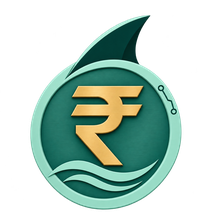
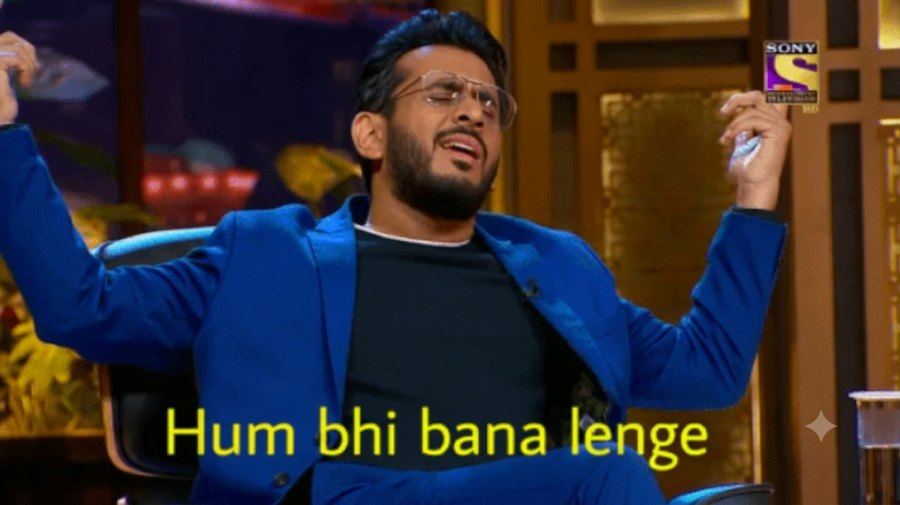
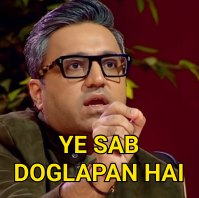

In [43]:
# ── Cell 43 ──
if "DASHBOARD_TEMPLATE" not in globals():
    print("Dashboard layout cell not loaded: paste it into the empty cell above to open the pitch desk.")
    print(f"The trained model is ready anyway: {winner}")
else:
    # Connect the interactive desk to the fitted model and its held-out evaluation.
    from html import escape
    from IPython.display import HTML, display

    dashboard_data["photos"] = REACTION_PHOTOS
    payload = json.dumps(dashboard_data, allow_nan=False, separators=(",", ":")).replace("<", r"\u003c")
    dashboard_html = DASHBOARD_TEMPLATE.replace("__DATA__", payload)
    dashboard_path = Path("simulated_pitch_dashboard.html")
    dashboard_path.write_text(dashboard_html, encoding="utf-8")
    print(f"Live model: {winner} | {len(X_train)} training pitches | {len(X_test)} test pitches")
    print(f"Offline copy: {dashboard_path.resolve()}")
    display(HTML('<iframe title="Interactive pitch desk" style="width:100%;height:900px;border:0" '
                 'srcdoc="' + escape(dashboard_html, quote=True) + '"></iframe>'))

# ✅ Student checklist

- I ran the notebook from the first cell to the last cell in order.
- I can explain what the target variable Deal means.
- I can explain why leakage columns must be excluded.
- I can explain why missing values are imputed instead of deleting rows.
- I can explain at least one engineered feature.
- I can explain the purpose of the train/test split.
- I can explain what the probability threshold changes.
- I can read a confusion matrix and compare model metrics.